# Lab 03 — Edge Detection and Its Impact on Skin-Lesion Classification (HAM10000)

Do classical edge maps help or hurt skin-lesion classification, compared with the raw (Lab 01) and
filtered (Lab 02) images?

| | |
|---|---|
| **Dataset** | [HAM10000](https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000) — 7 classes, 10,015 dermoscopic images (same as Lab 02) |
| **Edge detectors** | Sobel (G<sub>x</sub>, G<sub>y</sub>, magnitude), Prewitt, Laplacian, Laplacian of Gaussian (LoG), Canny |
| **Noise study** | Gaussian and salt-and-pepper noise, each followed by Gaussian or Median filtering |
| **Canny study** | the four configurations of Table 2, plus a threshold sweep over three kernel sizes |
| **Input sets** | **A** raw · **B** Median 3×3 (Lab 02's best filter) · **C** best edge map (chosen in §7) |
| **Classifiers** | SVM, Random Forest and KNN on frozen EfficientNet-B0 features · **EfficientNet-B0** and **ResNet50** fine-tuned end-to-end |
| **Metrics** | accuracy, macro precision / recall / F1, balanced accuracy, macro AUC, training time, inference time |

### Where each task lives
| Section | Task sheet |
|---|---|
| §3 Edge-detector toolkit | Task 1 — the detectors, written out as kernels and checked against OpenCV |
| §4 Comparative edge detection | Task 1 — the required figure |
| §5 Noise and smoothing | Task 2 — **Table 1** |
| §6 Canny parameters | Task 3 — **Table 2** |
| §7 Choosing the edge representation | Tasks 1–3 → 4 — "the best edge detection configuration" |
| §8 Sets A / B / C | Task 4 |
| §9–10 Training | Task 4 |
| §11 Results | Task 5 — **Table 3** |
| §12 Visual comparison | Task 6 — confusion matrices and bar charts |
| §13 What a CNN's first layer learns | Discussion Question 6 |
| §14–15 Cross-lab context, export | Question 7, and the numbers for Questions 1–7 |

### Why the comparison is fair
- **Lab 02's exact split.** Same grouped-stratified 70/15/15 split by `lesion_id`, same seed, same
  per-class caps. Set A's test images are exactly Lab 02's test images.
- **One split for all three sets.** A, B and C are three views of the *same* images; the input
  representation is the only thing that changes.
- **One recipe per model.** Every model sees all three sets with identical epochs, learning-rate
  schedule, augmentation, class-weighted loss and seed. Hyperparameters and the best epoch are picked on
  **validation** macro-F1; the test set is scored exactly once per run.
- **Edge thresholds are frozen on clean data.** In the noise study each detector's threshold is chosen
  (by Otsu) on the clean image, passed through the same preprocessing, and then held fixed when noise is
  added. A threshold re-tuned on every noisy image would drift upward and hide the very effect being
  measured.

### Cost
**About 20–25 min** end-to-end on a Colab T4. Most of it is fine-tuning: 2 CNNs × 3 sets × 12 epochs.

---
**Colab:** *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*.
**Kaggle:** *Settings → Accelerator → GPU T4*, switch *Internet* on, then *Run All*.

## 0 · Environment setup

In [1]:
# Colab already ships torch, torchvision, OpenCV, scikit-learn, scikit-image, pandas and matplotlib.
# Only kagglehub and python-docx are missing on a stock runtime (Kaggle already has kagglehub).
!pip install -q kagglehub python-docx

import os, sys, importlib, torch, torchvision
print("python      :", sys.version.split()[0])
print("torch       :", torch.__version__)
print("torchvision :", torchvision.__version__)
for mod in ("cv2", "skimage", "sklearn", "pandas", "matplotlib", "kagglehub", "docx", "psutil"):
    try:
        m = importlib.import_module(mod)
        print("%-12s: %s" % (mod, getattr(m, "__version__", "ok")))
    except ImportError:
        print("%-12s: MISSING" % mod)

IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = os.path.isdir("/kaggle/working")
print("\nPlatform    :", "Colab" if IN_COLAB else "Kaggle" if IN_KAGGLE else "local / other")
print("CUDA        :", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")
if not torch.cuda.is_available():
    print("\n*** No GPU detected. Switch to a T4 runtime, otherwise fine-tuning (Section 10) "
          "takes hours. ***")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 2.9 MB/s eta 0:00:00
python      : 3.13.15
torch       : 2.11.0+cu128
torchvision : 0.26.0+cu128
cv2         : 5.0.0
skimage     : 0.25.2
sklearn     : 1.6.1
pandas      : 2.2.3
matplotlib  : 3.10.0
kagglehub   : 1.0.2
docx        : 1.2.0
psutil      : 5.9.5

Platform    : Colab
CUDA        : True | Tesla T4


## 1 · Configuration and shared helpers

Every number you might want to change lives in `Config`. The data settings are deliberately
**identical to Lab 02**, so all three input sets are built from exactly the images Lab 02 used.

In [2]:
import json, math, random, shutil, time, warnings
from dataclasses import dataclass, asdict
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")


@dataclass
class Config:
    # ---- data: identical to Lab 02, so Sets A/B/C come from Lab 02's exact split ----
    img_size: int = 224
    val_fraction: float = 0.15
    test_fraction: float = 0.15
    max_train_per_class: int | None = 400     # None = every image (HAM10000 is 67% `nv`)
    max_eval_per_class: int | None = 120      # applied to val AND test
    seed: int = 42
    decode_workers: int = 8

    # ---- Tasks 1-3: edge detection (every border uses reflect-101 padding) ----
    task1_classes: tuple = ("mel", "nv", "bcc", "bkl")   # the sheet asks for >= 3 classes
    n_analysis_images: int = 70       # test images averaged over for Tables 1 and 2
    log_ksize: int = 5                # LoG = Gaussian(ksize, sigma), then the Laplacian
    log_sigma: float = 1.0
    canny_default: str = "Canny-4"    # the Canny used in Tasks 1-2 (see CANNY_CONFIGS)

    # ---- Task 2: noise and denoising ----
    gaussian_noise_sigma: float = 20.0    # grey levels, on a 0-255 image
    sp_amount: float = 0.05               # fraction of pixels hit: half salt, half pepper
    denoise_gaussian_ksize: int = 5       # the same Gaussian filter as Lab 02
    denoise_gaussian_sigma: float = 1.0
    denoise_median_ksize: int = 3         # the same Median filter as Lab 02 (= Set B)
    match_tolerance: int = 1              # px; edges this close count as the same edge

    # ---- Set C: None = the winner of the Section 7 screening, or force one, e.g. "Canny-2" ----
    setC_override: str | None = None

    # ---- SVM / Random Forest / KNN on frozen CNN features ----
    feature_backbone: str = "EfficientNet-B0"
    feat_batch_size: int = 128

    # ---- fine-tuned CNNs: one recipe, applied unchanged to all three sets ----
    cnn_models: tuple = ("EfficientNet-B0", "ResNet50")
    ft_epochs: int = 12
    ft_lr: float = 3e-4
    ft_weight_decay: float = 1e-4
    ft_batch_size: int = 32
    eval_batch_size: int = 128

    out_dir: str = "results"


cfg = Config()

# Table 2's configurations. `ksize` is the Gaussian smoothing kernel that opens the Canny algorithm;
# OpenCV derives sigma from it (3x3 -> 0.8, 5x5 -> 1.1). The sheet leaves Canny-4's thresholds open:
# 50/150 makes it identical to Canny-2 except for the kernel, so the pair isolates smoothing.
CANNY_CONFIGS = {
    "Canny-1": dict(low=30,  high=100, ksize=3),
    "Canny-2": dict(low=50,  high=150, ksize=3),
    "Canny-3": dict(low=100, high=200, ksize=3),
    "Canny-4": dict(low=50,  high=150, ksize=5),
}

HAM_FULL = {
    "akiec": "Actinic keratoses / intraepithelial carcinoma",
    "bcc":   "Basal cell carcinoma",
    "bkl":   "Benign keratosis-like lesions",
    "df":    "Dermatofibroma",
    "mel":   "Melanoma",
    "nv":    "Melanocytic nevi",
    "vasc":  "Vascular lesions",
}
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
IMG_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

# Earlier labs, kept here so Question 7 can be answered from this notebook.
# Lab 01: ISIC 9-class, frozen backbone + linear probe - a different dataset, so context only.
LAB01_TABLE1 = [
    # model,            test acc %, test macro-F1 %
    ("EfficientNet-B0", 57.6, 53.6),
    ("ResNet18",        51.7, 49.4),
    ("ResNet50",        49.2, 45.7),
    ("ResNet101",       47.5, 42.8),
    ("DenseNet121",     47.5, 45.1),
    ("VGG16",           39.8, 36.4),
    ("VGG19",           39.0, 34.3),
    ("AlexNet",         35.6, 31.0),
]
# Lab 02: HAM10000, the same split as here, frozen backbone + linear probe. Sobel accuracy was not
# carried over; its macro-F1 is the Lab 02 baseline plus the reported Sobel delta.
LAB02_REFERENCE = [
    # model,            input,        test acc %, test macro-F1 %
    ("EfficientNet-B0", "Raw",        59.8, 57.4),
    ("EfficientNet-B0", "Median 3x3", 59.4, 57.1),
    ("EfficientNet-B0", "Sobel",      None, 43.4),
    ("ResNet18",        "Raw",        55.6, 53.2),
    ("ResNet18",        "Median 3x3", 58.3, 57.8),
    ("ResNet18",        "Sobel",      None, 41.0),
    ("ResNet50",        "Raw",        57.0, 55.5),
    ("ResNet50",        "Median 3x3", 60.0, 59.9),
    ("ResNet50",        "Sobel",      None, 39.3),
]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"
if USE_AMP:
    torch.backends.cudnn.benchmark = True


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def cuda_sync():
    """Wait for queued GPU work, so wall-clock timings measure the work and not its launch."""
    if torch.cuda.is_available():
        torch.cuda.synchronize()


def free_memory():
    import gc
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def banner(text):
    print("\n" + "=" * 78)
    print(text)
    print("=" * 78)


# ---- plotting: the same validated palette as Lab 02 ----
# Categorical slots are used in order and never cycled; the order is the colour-vision safety net.
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
               "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQ_BLUE = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7", "#3987e5",
            "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
SEQ_ORANGE = ["#fde6da", "#f9c8ae", "#f4a47d", "#eb6834", "#c9531f", "#9c3f16"]  # 2nd magnitude
DIVERGING = ["#a32f2e", "#e34948", "#f2a3a2", "#f0efec", "#9ec5f4", "#2a78d6", "#1c5cab"]  # red worse, blue better
INK_PRIMARY, INK_SECONDARY, INK_MUTED = "#0b0b0b", "#52514e", "#898781"
SURFACE, GRID_C, REFERENCE_C = "#fcfcfb", "#e1e0d9", "#c3c2b7"
SET_COLORS = {"Raw": CATEGORICAL[0], "Filtered": CATEGORICAL[1], "Edge": CATEGORICAL[2]}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID_C, "axes.labelcolor": INK_SECONDARY,
    "text.color": INK_PRIMARY, "xtick.color": INK_SECONDARY,
    "ytick.color": INK_SECONDARY, "grid.color": GRID_C,
    "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 9, "figure.dpi": 110,
})


def cmap_from(colors, name="custom"):
    from matplotlib.colors import LinearSegmentedColormap
    return LinearSegmentedColormap.from_list(name, colors)


SEQ_CMAP = cmap_from(["#f4f8fd"] + SEQ_BLUE, "seq_blue")   # near-zero recedes to the surface


def label_line_ends(ax, x, ys, labels):
    """Direct labels at the right end of lines, nudged apart so they never overlap."""
    lo, hi = ax.get_ylim()
    gap = 0.06 * (hi - lo)
    last = -np.inf
    for k in np.argsort(np.nan_to_num(ys, nan=-np.inf)):
        if np.isnan(ys[k]):
            continue
        y = max(ys[k], last + gap)
        ax.text(x, y, labels[k], va="center", fontsize=8, color=INK_SECONDARY)
        last = y


def bare(ax):
    """Image panel: no ticks, no frame."""
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)


FIGURES = {}   # name -> (png path, caption), in creation order; embedded in the .docx at the end


def save_fig(fig, name, caption):
    out = Path(cfg.out_dir)
    out.mkdir(parents=True, exist_ok=True)
    path = out / ("%s.png" % name)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    FIGURES[name] = (str(path), caption)
    plt.show()
    plt.close(fig)


os.makedirs(cfg.out_dir, exist_ok=True)
set_seed(cfg.seed)

banner("RUNTIME CHECK")
if device.type == "cuda":
    p = torch.cuda.get_device_properties(0)
    print("  GPU        : %s (%.1f GB VRAM), mixed precision on" % (p.name, p.total_memory / 1024 ** 3))
else:
    print("  GPU        : NONE - running on CPU")
try:
    import psutil
    vm = psutil.virtual_memory()
    print("  System RAM : %.1f GB total, %.1f GB available" % (vm.total / 1024 ** 3, vm.available / 1024 ** 3))
except ImportError:
    pass
print("  Split      : %d/%d/%d, train <= %s, val/test <= %s per class (= Lab 02)"
      % (round(100 * (1 - cfg.val_fraction - cfg.test_fraction)), round(100 * cfg.val_fraction),
         round(100 * cfg.test_fraction), cfg.max_train_per_class, cfg.max_eval_per_class))
print("  Canny      :", ", ".join("%s %d/%d %dx%d" % (n, c["low"], c["high"], c["ksize"], c["ksize"])
                                  for n, c in CANNY_CONFIGS.items()))
print("  Classifiers: SVM, Random Forest, KNN on frozen %s features; fine-tuned %s"
      % (cfg.feature_backbone, " + ".join(cfg.cnn_models)))


RUNTIME CHECK
  GPU        : Tesla T4 (14.6 GB VRAM), mixed precision on
  System RAM : 12.7 GB total, 10.6 GB available
  Split      : 70/15/15, train <= 400, val/test <= 120 per class (= Lab 02)
  Canny      : Canny-1 30/100 3x3, Canny-2 50/150 3x3, Canny-3 100/200 3x3, Canny-4 50/150 5x5
  Classifiers: SVM, Random Forest, KNN on frozen EfficientNet-B0 features; fine-tuned EfficientNet-B0 + ResNet50


> **No GPU?** If the check above says `GPU : NONE`, either switch to a T4 and re-run from the top, or
> uncomment the reduced configuration below **before Section 2**. It still produces every table and
> figure, just on less data and with a lighter second CNN.

In [3]:
# --- CPU / low-quota fallback: uncomment only if you have no GPU ---
# cfg.max_train_per_class = 60
# cfg.max_eval_per_class  = 40
# cfg.ft_epochs           = 4
# cfg.cnn_models          = ("EfficientNet-B0", "ResNet18")
# print("Reduced config:", cfg.max_train_per_class, "train/class,", cfg.max_eval_per_class, "eval/class")

---
## 2 · Dataset — HAM10000 with Lab 02's exact split

`kagglehub.dataset_download` returns the folder the archive was unpacked into. We need the JPEGs,
not just a CSV, so this is the right call rather than `kagglehub.load_dataset`.

In [4]:
import kagglehub

path = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
Path to dataset files: /kaggle/input/skin-cancer-mnist-ham10000


### Split and decode into RAM

This is Lab 02's loader, unchanged: index every JPEG, join it to `HAM10000_metadata.csv`, make the
**grouped** stratified 70/15/15 split (whole lesions go to one split), apply the per-class caps and
decode everything once into a `uint8` array. Same code and same seed produce the same split, and every
later section reads pixels from RAM.

In [5]:
def index_images(root):
    """image_id (filename stem) -> path, for every image under root (handles part_1 / part_2)."""
    index = {}
    for dirpath, _dirs, files in os.walk(root):
        for fn in files:
            stem, ext = os.path.splitext(fn)
            if ext.lower() in IMG_EXTENSIONS:
                index.setdefault(stem, os.path.join(dirpath, fn))
    return index


def load_records(root):
    """(classes, [(path, label, lesion_id), ...]) from HAM10000_metadata.csv."""
    index = index_images(root)
    meta = None
    for dirpath, _dirs, files in os.walk(root):
        for fn in files:
            if fn.lower().startswith("ham10000_metadata"):
                try:
                    df = pd.read_csv(os.path.join(dirpath, fn))
                except Exception:
                    continue
                if {"image_id", "dx", "lesion_id"}.issubset(df.columns):
                    meta = df
                    break
        if meta is not None:
            break
    if meta is None:
        raise FileNotFoundError("HAM10000_metadata.csv not found under %s" % root)

    classes = sorted(set(meta["dx"].astype(str)))
    cls_to_idx = {c: i for i, c in enumerate(classes)}
    records, missing = [], 0
    for row in meta.itertuples(index=False):
        p = index.get(str(row.image_id))
        if p is None:
            missing += 1
            continue
        records.append((p, cls_to_idx[str(row.dx)], str(row.lesion_id)))
    print("Indexed %d images: %d labelled, %d lesions, %d classes (%s)%s"
          % (len(index), len(records), len({g for _p, _l, g in records}), len(classes),
             ", ".join(classes), "; %d metadata rows had no image" % missing if missing else ""))
    return classes, records


def grouped_stratified_split(records, val_fraction, test_fraction, seed):
    """Lab 02's split: per class, whole lesion groups go to test, then val, the rest to train."""
    rng = random.Random(seed)
    groups = {}
    for p, label, gid in records:
        groups.setdefault((label, gid), []).append((p, label))
    by_class = {}
    for (label, _gid), items in groups.items():
        by_class.setdefault(label, []).append(items)

    train, val, test = [], [], []
    for label in sorted(by_class):
        glist = by_class[label]
        rng.shuffle(glist)
        n_total = sum(len(g) for g in glist)
        want_test = int(round(n_total * test_fraction))
        want_val = int(round(n_total * val_fraction))
        acc_test, acc_val, i = [], [], 0
        while i < len(glist) - 1 and len(acc_test) < want_test:
            acc_test.extend(glist[i]); i += 1
        while i < len(glist) - 1 and len(acc_val) < want_val:
            acc_val.extend(glist[i]); i += 1
        test.extend(acc_test)
        val.extend(acc_val)
        train.extend(it for g in glist[i:] for it in g)
    rng.shuffle(train); rng.shuffle(val); rng.shuffle(test)
    return train, val, test


def cap_per_class(items, cap, seed):
    """Subsample each class down to `cap` items (Lab 02's runtime dial)."""
    if cap is None:
        return items
    rng = random.Random(seed)
    by_class = {}
    for it in items:
        by_class.setdefault(it[1], []).append(it)
    out = []
    for label in sorted(by_class):
        group = by_class[label][:]
        rng.shuffle(group)
        out.extend(group[:cap])
    rng.shuffle(out)
    return out


def load_one(path, size):
    """Resize the shorter side to 1.14*size and centre-crop size x size (Lab 02's preprocessing)."""
    with Image.open(path) as im:
        im = im.convert("RGB")
        target = int(round(size * 1.14))
        w, h = im.size
        if w < h:
            nw, nh = target, max(target, int(round(h * target / w)))
        else:
            nh, nw = target, max(target, int(round(w * target / h)))
        im = im.resize((nw, nh), Image.BILINEAR)
        left, top = (nw - size) // 2, (nh - size) // 2
        return np.asarray(im.crop((left, top, left + size, top + size)), dtype=np.uint8)


def decode_split(items, size, workers, desc):
    """Decode a whole split into one uint8 array [N, H, W, 3] (RGB) plus its labels."""
    out = np.empty((len(items), size, size, 3), np.uint8)

    def work(i):
        out[i] = load_one(items[i][0], size)

    t0 = time.time()
    with ThreadPoolExecutor(max_workers=workers) as ex:
        list(ex.map(work, range(len(items))))
    print("  decoded %-5s %5d images  (%4.0f MB, %4.1fs)"
          % (desc, len(items), out.nbytes / 1024 ** 2, time.time() - t0))
    return out, np.array([label for _p, label in items], dtype=np.int64)


classes, records = load_records(path)
N_CLASSES = len(classes)
LABELS = list(range(N_CLASSES))

train_items, val_items, test_items = grouped_stratified_split(
    records, cfg.val_fraction, cfg.test_fraction, cfg.seed)
print("Grouped-stratified split :  train=%d  val=%d  test=%d"
      % (len(train_items), len(val_items), len(test_items)))
train_items = cap_per_class(train_items, cfg.max_train_per_class, cfg.seed)
val_items = cap_per_class(val_items, cfg.max_eval_per_class, cfg.seed)
test_items = cap_per_class(test_items, cfg.max_eval_per_class, cfg.seed)
print("After per-class caps     :  train=%d  val=%d  test=%d    (Lab 02: 1969 / 524 / 525)"
      % (len(train_items), len(val_items), len(test_items)))

print("\nDecoding into a RAM cache (the only time the JPEGs are read):")
X, Y = {}, {}
for split, items in (("train", train_items), ("val", val_items), ("test", test_items)):
    X[split], Y[split] = decode_split(items, cfg.img_size, cfg.decode_workers, split)

Indexed 10015 images: 10015 labelled, 7470 lesions, 7 classes (akiec, bcc, bkl, df, mel, nv, vasc)
Grouped-stratified split :  train=7004  val=1504  test=1507
After per-class caps     :  train=1969  val=524  test=525    (Lab 02: 1969 / 524 / 525)

Decoding into a RAM cache (the only time the JPEGs are read):
  decoded train  1969 images  ( 283 MB, 14.2s)
  decoded val     524 images  (  75 MB,  3.3s)
  decoded test    525 images  (  75 MB,  3.3s)


In [6]:
# Sanity check: no LESION may appear in more than one split (stricter than checking file names).
lesion_of = {p: g for p, _l, g in records}
lesions = {s: {lesion_of[p] for p, _l in items}
           for s, items in (("train", train_items), ("val", val_items), ("test", test_items))}
print("Lesions shared between splits:  train&val=%d  train&test=%d  val&test=%d   (must all be 0)"
      % (len(lesions["train"] & lesions["val"]), len(lesions["train"] & lesions["test"]),
         len(lesions["val"] & lesions["test"])))

CLASS_COUNTS = pd.DataFrame({
    "Code": classes,
    "Class": [HAM_FULL.get(c, c) for c in classes],
    "Full dataset": np.bincount([l for _p, l, _g in records], minlength=N_CLASSES),
    "Train": np.bincount(Y["train"], minlength=N_CLASSES),
    "Val": np.bincount(Y["val"], minlength=N_CLASSES),
    "Test": np.bincount(Y["test"], minlength=N_CLASSES),
})
display(CLASS_COUNTS)

Lesions shared between splits:  train&val=0  train&test=0  val&test=0   (must all be 0)


,Code,Class,Full dataset,Train,Val,Test
0,akiec,Actinic keratoses / intraepithelial carcinoma,327,229,49,49
1,bcc,Basal cell carcinoma,514,360,77,77
2,bkl,Benign keratosis-like lesions,1099,400,120,120
3,df,Dermatofibroma,115,80,17,18
4,mel,Melanoma,1113,400,120,120
5,nv,Melanocytic nevi,6705,400,120,120
6,vasc,Vascular lesions,142,100,21,21


---
## 3 · Edge-detector toolkit (Task 1)

Every detector is written out as its kernel and applied with `cv2.filter2D` (a correlation, which is
exactly what Lab 02's Q9 discussed). All of them work on the grey-level (luma) image.

| Detector | Order | Kernel | Output |
|---|---|---|---|
| **Sobel** | 1st | $G_x$ = `[[-1,0,1],[-2,0,2],[-1,0,1]]`, $G_y = G_x^T$ | $G_x$, $G_y$, $\lvert G\rvert=\sqrt{G_x^2+G_y^2}$ |
| **Prewitt** | 1st | `[[-1,0,1],[-1,0,1],[-1,0,1]]` and its transpose | $\lvert G\rvert$ |
| **Laplacian** | 2nd | `[[0,1,0],[1,-4,1],[0,1,0]]` | $\nabla^2 I$ — edges are its zero crossings |
| **LoG** | 2nd | 5×5 Gaussian (σ = 1), then the Laplacian | $\nabla^2(G * I)$ — edges are its zero crossings |
| **Canny** | multi-stage | Gaussian → Sobel → non-maximum suppression → hysteresis | binary, 1 px wide |

Note that `cv2.Canny` does **not** smooth on its own. It runs the last three stages, so the Gaussian
stage is done explicitly (the kernel size of Table 2).

**Binary edge maps.** Tasks 2 and 3 need edges you can count and compare, so each continuous response
is turned into an edge / no-edge map:
- **first-order** (Sobel, Prewitt): $\lvert G\rvert > T$;
- **second-order** (Laplacian, LoG): a zero crossing whose jump across the crossing exceeds $T$
  (Marr–Hildreth);
- $T$ is picked by **Otsu's method on the clean image** and then frozen. In Task 2 the clean image first
  goes through the same filter as the noisy one, so each filter + detector pipeline is calibrated on
  clean data before any noise is added. This matters because smoothing shrinks second-derivative
  responses far more than first-derivative ones, so a threshold from the unfiltered image would wrongly
  erase every Laplacian edge after filtering;
- **Canny** already outputs a binary map through its own hysteresis thresholds.

In [7]:
BORDER = cv2.BORDER_REFLECT_101

SOBEL_X   = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
SOBEL_Y   = SOBEL_X.T.copy()
PREWITT_X = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
PREWITT_Y = PREWITT_X.T.copy()
LAPLACE_4 = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], np.float32)

DETECTORS = ("Sobel", "Prewitt", "Laplacian", "LoG", "Canny")


def gray_u8(rgb):
    """RGB uint8 -> luma uint8 (BT.601 weights, as in Lab 02's Sobel)."""
    return cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)


def correlate(gray, kernel):
    """2-D correlation with a small kernel; float32 in, float32 out, reflect-101 borders."""
    return cv2.filter2D(gray.astype(np.float32), cv2.CV_32F, kernel, borderType=BORDER)


def sobel(gray):
    gx, gy = correlate(gray, SOBEL_X), correlate(gray, SOBEL_Y)
    return gx, gy, np.sqrt(gx * gx + gy * gy)


def prewitt(gray):
    gx, gy = correlate(gray, PREWITT_X), correlate(gray, PREWITT_Y)
    return gx, gy, np.sqrt(gx * gx + gy * gy)


def laplacian(gray):
    return correlate(gray, LAPLACE_4)


def log_filter(gray, ksize, sigma):
    """Laplacian of Gaussian: smooth first, so the 2nd derivative stops amplifying pixel noise."""
    smooth = cv2.GaussianBlur(gray.astype(np.float32), (ksize, ksize), sigma, borderType=BORDER)
    return correlate(smooth, LAPLACE_4)


def canny(gray, low, high, ksize):
    """Canny: Gaussian smoothing here, then cv2.Canny's gradient / non-max suppression / hysteresis.

    L2gradient=True uses the true magnitude sqrt(Gx^2 + Gy^2) instead of |Gx| + |Gy|.
    """
    smooth = cv2.GaussianBlur(gray, (ksize, ksize), 0, borderType=BORDER)
    return cv2.Canny(smooth, low, high, L2gradient=True) > 0


def response(gray, name):
    """Continuous response: |G| for first-order detectors, the signed 2nd derivative otherwise."""
    if name == "Sobel":
        return sobel(gray)[2]
    if name == "Prewitt":
        return prewitt(gray)[2]
    if name == "Laplacian":
        return laplacian(gray)
    if name == "LoG":
        return log_filter(gray, cfg.log_ksize, cfg.log_sigma)
    raise ValueError(name)


def crossing_jumps(r):
    """Jump |r(p) - r(q)| at every zero crossing of r (p vs its right or lower neighbour), else 0."""
    pos = r > 0
    jump = np.zeros_like(r)
    h = pos[:, :-1] != pos[:, 1:]
    jump[:, :-1] = np.where(h, np.abs(r[:, :-1] - r[:, 1:]), 0)
    v = pos[:-1, :] != pos[1:, :]
    jump[:-1, :] = np.maximum(jump[:-1, :], np.where(v, np.abs(r[:-1, :] - r[1:, :]), 0))
    return jump


def otsu(values, bins=256):
    """Otsu's threshold for arbitrary float values (cv2's Otsu only accepts uint8 images)."""
    v = np.asarray(values, np.float64).ravel()
    if v.size == 0 or v.max() <= v.min():
        return float(v.max()) if v.size else 0.0
    hist, edges = np.histogram(v, bins=bins)
    centers = 0.5 * (edges[:-1] + edges[1:])
    w0 = np.cumsum(hist).astype(np.float64)
    w1 = w0[-1] - w0
    m0 = np.cumsum(hist * centers)
    mu0 = m0 / np.maximum(w0, 1)
    mu1 = (m0[-1] - m0) / np.maximum(w1, 1)
    return float(edges[np.argmax(w0 * w1 * (mu0 - mu1) ** 2) + 1])


def calibrate(gray, name):
    """Edge threshold for detector `name`, picked by Otsu on a CLEAN image (None for Canny)."""
    if name == "Canny":
        return None
    r = response(gray, name)
    if name in ("Sobel", "Prewitt"):
        return otsu(r)
    j = crossing_jumps(r)
    return otsu(j[j > 0])


def edge_map(gray, name, thr, canny_name=None):
    """Binary edge map. `thr` comes from calibrate() on the clean version of this image."""
    if name == "Canny":
        return canny(gray, **CANNY_CONFIGS[canny_name or cfg.canny_default])
    r = response(gray, name)
    if name in ("Sobel", "Prewitt"):
        return r > thr
    return crossing_jumps(r) > thr


def show_mag(r):
    """Display scaling for |response|: the per-image 99th percentile maps to white."""
    a = np.abs(r)
    return np.clip(a / max(float(np.percentile(a, 99)), 1e-6), 0, 1)


def show_signed(r):
    """Display scaling for signed gradients: mid-grey = 0, bright = positive, dark = negative."""
    q = max(float(np.percentile(np.abs(r), 99)), 1e-6)
    return np.clip(0.5 + 0.5 * r / q, 0, 1)

### Check the hand-written kernels against OpenCV's built-in operators
OpenCV has no Prewitt operator, so Prewitt is checked against its separable form: a `[-1, 0, 1]`
derivative across the image times a `[1, 1, 1]` box along it.

In [8]:
g = gray_u8(X["test"][0]).astype(np.float32)
checks = [
    ("Sobel G_x", "cv2.Sobel(dx=1)", sobel(g)[0], cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3, borderType=BORDER)),
    ("Sobel G_y", "cv2.Sobel(dy=1)", sobel(g)[1], cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3, borderType=BORDER)),
    ("Prewitt G_x", "cv2.sepFilter2D", prewitt(g)[0],
     cv2.sepFilter2D(g, cv2.CV_32F, np.float32([-1, 0, 1]), np.float32([1, 1, 1]), borderType=BORDER)),
    ("Prewitt G_y", "cv2.sepFilter2D", prewitt(g)[1],
     cv2.sepFilter2D(g, cv2.CV_32F, np.float32([1, 1, 1]), np.float32([-1, 0, 1]), borderType=BORDER)),
    ("Laplacian", "cv2.Laplacian(ksize=1)", laplacian(g), cv2.Laplacian(g, cv2.CV_32F, ksize=1, borderType=BORDER)),
]
display(pd.DataFrame([{"Operator": n, "OpenCV reference": ref, "max |mine - OpenCV|": float(np.abs(a - b).max())}
                      for n, ref, a, b in checks]))

for name, k in (("Sobel G_x", SOBEL_X), ("Sobel G_y", SOBEL_Y), ("Prewitt G_x", PREWITT_X),
                ("Prewitt G_y", PREWITT_Y), ("Laplacian", LAPLACE_4)):
    print("%-12s" % name, str(k.astype(int).tolist()))

,Operator,OpenCV reference,max |mine - OpenCV|
0,Sobel G_x,cv2.Sobel(dx=1),0.0
1,Sobel G_y,cv2.Sobel(dy=1),0.0
2,Prewitt G_x,cv2.sepFilter2D,0.0
3,Prewitt G_y,cv2.sepFilter2D,0.0
4,Laplacian,cv2.Laplacian(ksize=1),0.0


Sobel G_x    [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]
Sobel G_y    [[-1, -2, -1], [0, 0, 0], [1, 2, 1]]
Prewitt G_x  [[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]]
Prewitt G_y  [[-1, -1, -1], [0, 0, 0], [1, 1, 1]]
Laplacian    [[0, 1, 0], [1, -4, 1], [0, 1, 0]]


---
## 4 · Task 1 — Comparative edge detection

One test image from each of four classes (the sheet asks for at least three), run through every
detector. **This is the required figure:** Original → Sobel → Prewitt → Laplacian → LoG → Canny.
Sobel's two directional components are shown as well.

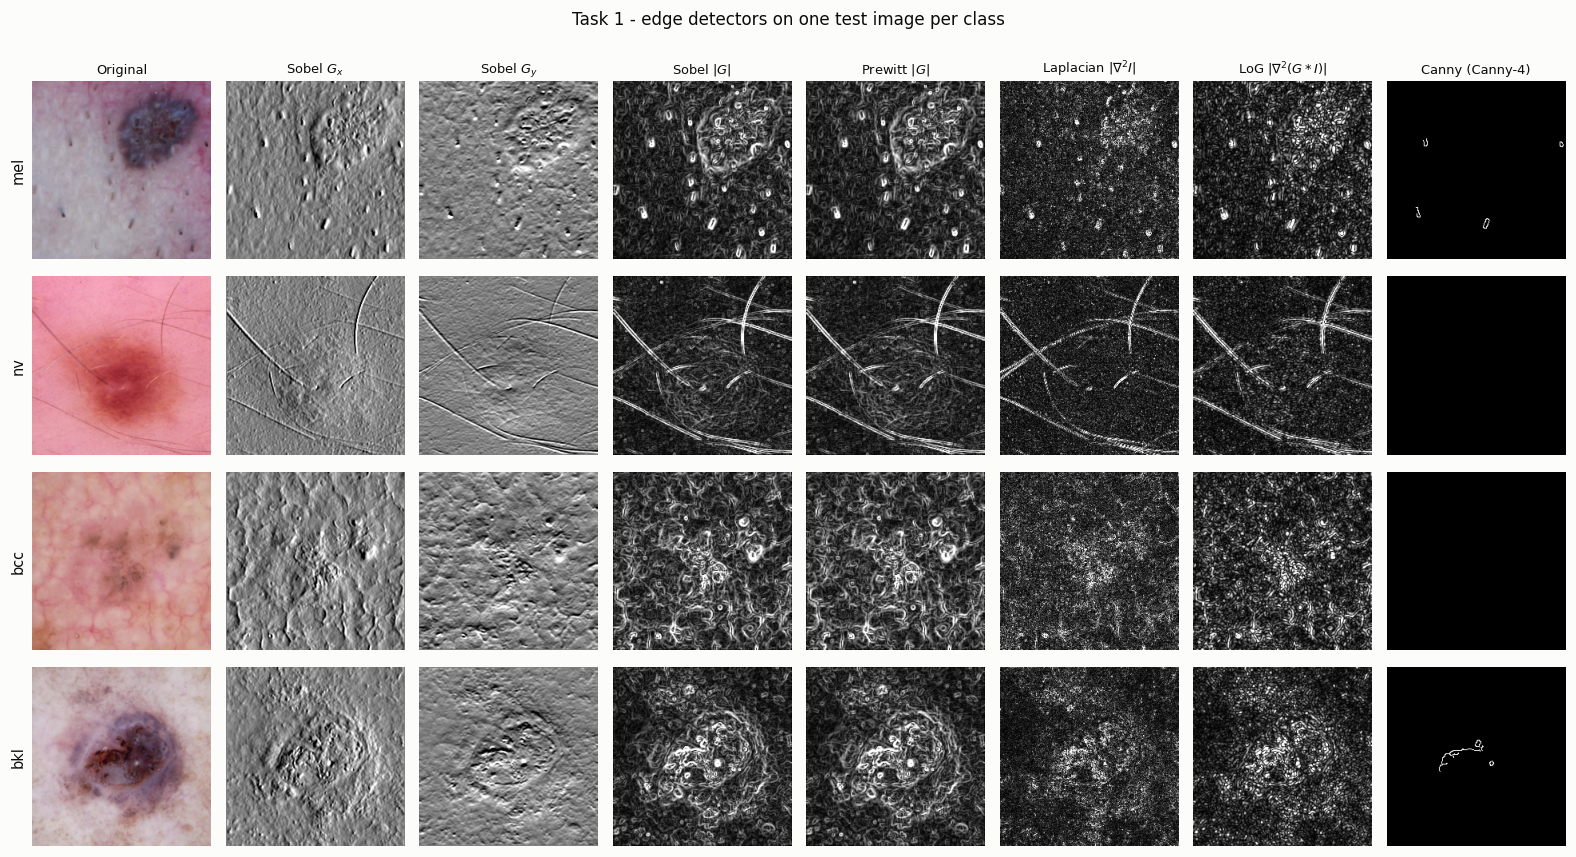

In [9]:
def pick_examples(split, codes, seed):
    """One deterministic example image per requested class."""
    rng = random.Random(seed)
    picks = []
    for code_ in codes:
        idx = [i for i, y in enumerate(Y[split]) if classes[y] == code_]
        if idx:
            picks.append(rng.choice(idx))
    return picks


EXAMPLES = pick_examples("test", cfg.task1_classes, cfg.seed)

cols = ["Original", r"Sobel $G_x$", r"Sobel $G_y$", r"Sobel $|G|$", r"Prewitt $|G|$",
        r"Laplacian $|\nabla^2 I|$", r"LoG $|\nabla^2 (G * I)|$", "Canny (%s)" % cfg.canny_default]
fig, axes = plt.subplots(len(EXAMPLES), len(cols), figsize=(1.8 * len(cols), 1.95 * len(EXAMPLES)),
                         squeeze=False)
for r, i in enumerate(EXAMPLES):
    rgb = X["test"][i]
    g = gray_u8(rgb)
    gx, gy, mag = sobel(g)
    panels = [rgb, show_signed(gx), show_signed(gy), show_mag(mag), show_mag(prewitt(g)[2]),
              show_mag(laplacian(g)), show_mag(log_filter(g, cfg.log_ksize, cfg.log_sigma)),
              canny(g, **CANNY_CONFIGS[cfg.canny_default]).astype(float)]
    for c, img in enumerate(panels):
        ax = axes[r, c]
        if c == 0:
            ax.imshow(img)
        else:
            ax.imshow(img, cmap="gray", vmin=0, vmax=1)
        bare(ax)
        if r == 0:
            ax.set_title(cols[c], fontsize=8.5, pad=5)
        if c == 0:
            ax.set_ylabel(classes[Y["test"][i]], fontsize=9.5, color=INK_PRIMARY)
fig.suptitle("Task 1 - edge detectors on one test image per class", fontsize=11, y=1.0)
fig.tight_layout()
save_fig(fig, "task1_edge_comparison",
         "Figure 1. Original -> Sobel (Gx, Gy, |G|) -> Prewitt -> Laplacian -> LoG -> Canny, one test image "
         "per class. Gx/Gy: mid-grey = 0. Magnitudes are scaled by their 99th percentile. Canny: %s."
         % cfg.canny_default)

### The same detectors as binary edge maps
These are the maps Tasks 2 and 3 count and compare, with thresholds set by Otsu on each clean image.
The corner label is the share of pixels marked as edge.

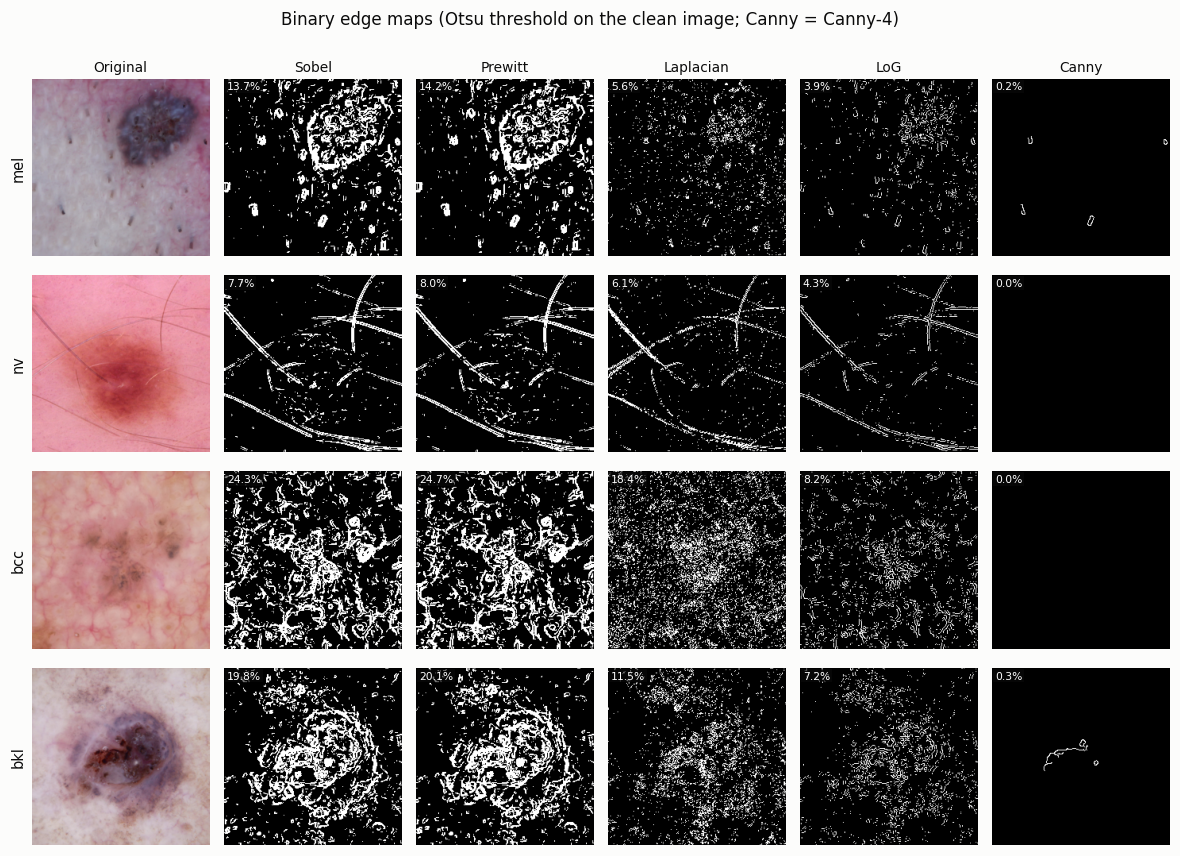

In [10]:
cols = ["Original"] + list(DETECTORS)
fig, axes = plt.subplots(len(EXAMPLES), len(cols), figsize=(1.8 * len(cols), 1.95 * len(EXAMPLES)),
                         squeeze=False)
for r, i in enumerate(EXAMPLES):
    rgb = X["test"][i]
    g = gray_u8(rgb)
    axes[r, 0].imshow(rgb)
    for c, d in enumerate(DETECTORS, start=1):
        e = edge_map(g, d, calibrate(g, d))
        axes[r, c].imshow(e, cmap="gray", vmin=0, vmax=1)
        axes[r, c].text(3, 3, "%.1f%%" % (100 * e.mean()), color="#ffffff", fontsize=7, va="top",
                        bbox=dict(facecolor=INK_PRIMARY, alpha=0.55, edgecolor="none", pad=1.2))
    for c in range(len(cols)):
        bare(axes[r, c])
        if r == 0:
            axes[r, c].set_title(cols[c], fontsize=9, pad=5)
    axes[r, 0].set_ylabel(classes[Y["test"][i]], fontsize=9.5, color=INK_PRIMARY)
fig.suptitle("Binary edge maps (Otsu threshold on the clean image; Canny = %s)" % cfg.canny_default,
             fontsize=11, y=1.0)
fig.tight_layout()
save_fig(fig, "task1_binary_edges",
         "Figure 2. Binary edge maps used for measurement. First-order: |G| > Otsu threshold. "
         "Second-order: zero crossings with a jump above the Otsu threshold. Label = share of edge pixels.")

---
## 5 · Task 2 — Effect of noise and smoothing

**Noise** is added to the grey image the detectors see. Adding it to RGB and then converting to grey
would quietly average the Gaussian noise down and blend the salt-and-pepper impulses.
- *Gaussian:* $I + \mathcal{N}(0, \sigma^2)$ with $\sigma$ = 20 grey levels, clipped to [0, 255].
- *Salt-and-pepper:* 5% of pixels are forced to 0 or 255 (half each).

**Inputs, as the sheet lists them:** the original image, the noisy image, the noisy image after a
Gaussian filter (5×5, σ = 1) and after a Median filter (3×3). Both filters are the ones used in
Lab 02, and each is applied to both noise types, which gives 7 conditions × 5 detectors. Every
detector sees the *same* noisy image.

**How each point the sheet asks you to comment on is measured.** Numbers are averaged over 70 test
images, 10 per class.

| Sheet asks about | Measured as |
|---|---|
| Edge continuity | **Mean fragment** — pixels per 8-connected edge segment (longer = more continuous) |
| Edge sharpness | **Thickness** — edge pixels ÷ skeleton pixels (1.0 = crisp 1-px edges) |
| False edges | **False edges %** — detected pixels more than 1 px from any clean-image edge; **Specks %** — fragments under 10 px |
| Broken edges | **Missed edges %** — clean-image edges not found again; more **Fragments** |
| Noise sensitivity | **F1 vs clean** (tolerant F1 of the noisy edge map against the clean one) and **edge inflation** (edge pixels ÷ clean edge pixels) |
| Effect of smoothing | the same numbers with and without the filter |

In [11]:
def add_gaussian_noise(gray, sigma, rng):
    noisy = gray.astype(np.float32) + rng.normal(0.0, sigma, gray.shape).astype(np.float32)
    return np.clip(np.rint(noisy), 0, 255).astype(np.uint8)


def add_salt_pepper(gray, amount, rng):
    out = gray.copy()
    u = rng.random(gray.shape)
    out[u < amount / 2] = 0            # pepper
    out[u > 1 - amount / 2] = 255      # salt
    return out


def gaussian_filter(gray):
    k = cfg.denoise_gaussian_ksize
    return cv2.GaussianBlur(gray, (k, k), cfg.denoise_gaussian_sigma, borderType=BORDER)


def median_filter(gray):
    return cv2.medianBlur(gray, cfg.denoise_median_ksize)


PREPS = ("None", "Gaussian Filter", "Median Filter")
CONDITIONS = [("None", "None")] + [(n, p) for n in ("Gaussian", "Salt & Pepper") for p in PREPS]
SHORT = {("None", "None"): "Original",
         ("Gaussian", "None"): "Gauss noise", ("Gaussian", "Gaussian Filter"): "Gauss + GF",
         ("Gaussian", "Median Filter"): "Gauss + MF",
         ("Salt & Pepper", "None"): "S&P noise", ("Salt & Pepper", "Gaussian Filter"): "S&P + GF",
         ("Salt & Pepper", "Median Filter"): "S&P + MF"}
NOISE_ID = {"None": 0, "Gaussian": 1, "Salt & Pepper": 2}


def noise_seed(img_idx, noise):
    """One fixed noise draw per (image, noise type): every detector and filter sees the same pixels."""
    return cfg.seed * 1_000_003 + img_idx * 10 + NOISE_ID[noise]


def preprocess(gray, prep):
    if prep == "Gaussian Filter":
        return gaussian_filter(gray)
    if prep == "Median Filter":
        return median_filter(gray)
    return gray


def make_condition(gray, noise, prep, seed):
    rng = np.random.default_rng(seed)
    if noise == "Gaussian":
        gray = add_gaussian_noise(gray, cfg.gaussian_noise_sigma, rng)
    elif noise == "Salt & Pepper":
        gray = add_salt_pepper(gray, cfg.sp_amount, rng)
    return preprocess(gray, prep)


def pipeline_thresholds(clean):
    """Threshold of every (detector, preprocessing) pipeline, calibrated on the CLEAN image run
    through that same preprocessing, then frozen for the noisy input."""
    return {(d, p): calibrate(preprocess(clean, p), d) for d in DETECTORS for p in PREPS}


TOL_KERNEL = cv2.getStructuringElement(cv2.MORPH_RECT, (2 * cfg.match_tolerance + 1,) * 2)


def match(pred, ref):
    """Tolerant (precision, recall, F1) of edge map `pred` against the reference map `ref`.

    precision = share of detected pixels within `match_tolerance` px of a reference edge
                (1 - precision = FALSE-edge rate)
    recall    = share of reference edge pixels found again (1 - recall = MISSED-edge rate)
    If the reference has no edges at all, recall and F1 are undefined (NaN) and drop out of the means.
    """
    n_pred, n_ref = int(pred.sum()), int(ref.sum())
    ref_zone = cv2.dilate(ref.astype(np.uint8), TOL_KERNEL) > 0
    pred_zone = cv2.dilate(pred.astype(np.uint8), TOL_KERNEL) > 0
    p = (pred & ref_zone).sum() / n_pred if n_pred else 1.0       # nothing detected -> nothing false
    if not n_ref:
        return p, np.nan, np.nan
    r = (ref & pred_zone).sum() / n_ref
    return p, r, (2 * p * r / (p + r) if p + r else 0.0)


try:
    from skimage.morphology import skeletonize
except ImportError:
    skeletonize = None
    print("[warn] scikit-image missing - edge thickness will be reported as NaN")


def structure(edges):
    """Continuity / sharpness statistics of one binary edge map."""
    n_px = int(edges.sum())
    n, _labels, stats, _cent = cv2.connectedComponentsWithStats(edges.astype(np.uint8), connectivity=8)
    sizes = stats[1:, cv2.CC_STAT_AREA]
    thick = n_px / max(int(skeletonize(edges).sum()), 1) if (skeletonize is not None and n_px) else np.nan
    return {
        "Edge px (%)": 100.0 * n_px / edges.size,
        "Fragments": n - 1,
        "Mean fragment (px)": float(sizes.mean()) if len(sizes) else 0.0,
        "Specks (%)": 100.0 * float((sizes < 10).mean()) if len(sizes) else 0.0,
        "Thickness (px)": thick,
    }


def stratified_sample(labels, n, seed):
    """About n indices, the same number from every class."""
    rng = random.Random(seed)
    by_class = {}
    for i, y in enumerate(labels):
        by_class.setdefault(int(y), []).append(i)
    per = max(1, n // len(by_class))
    out = []
    for c in sorted(by_class):
        idx = by_class[c][:]
        rng.shuffle(idx)
        out.extend(idx[:per])
    return sorted(out)


ANALYSIS_IDX = stratified_sample(Y["test"], cfg.n_analysis_images, cfg.seed)
print("Tables 1 and 2 average over %d test images (%s per class)."
      % (len(ANALYSIS_IDX), ", ".join("%s %d" % (classes[c], sum(Y["test"][i] == c for i in ANALYSIS_IDX))
                                      for c in LABELS)))

Tables 1 and 2 average over 70 test images (akiec 10, bcc 10, bkl 10, df 10, mel 10, nv 10, vasc 10 per class).


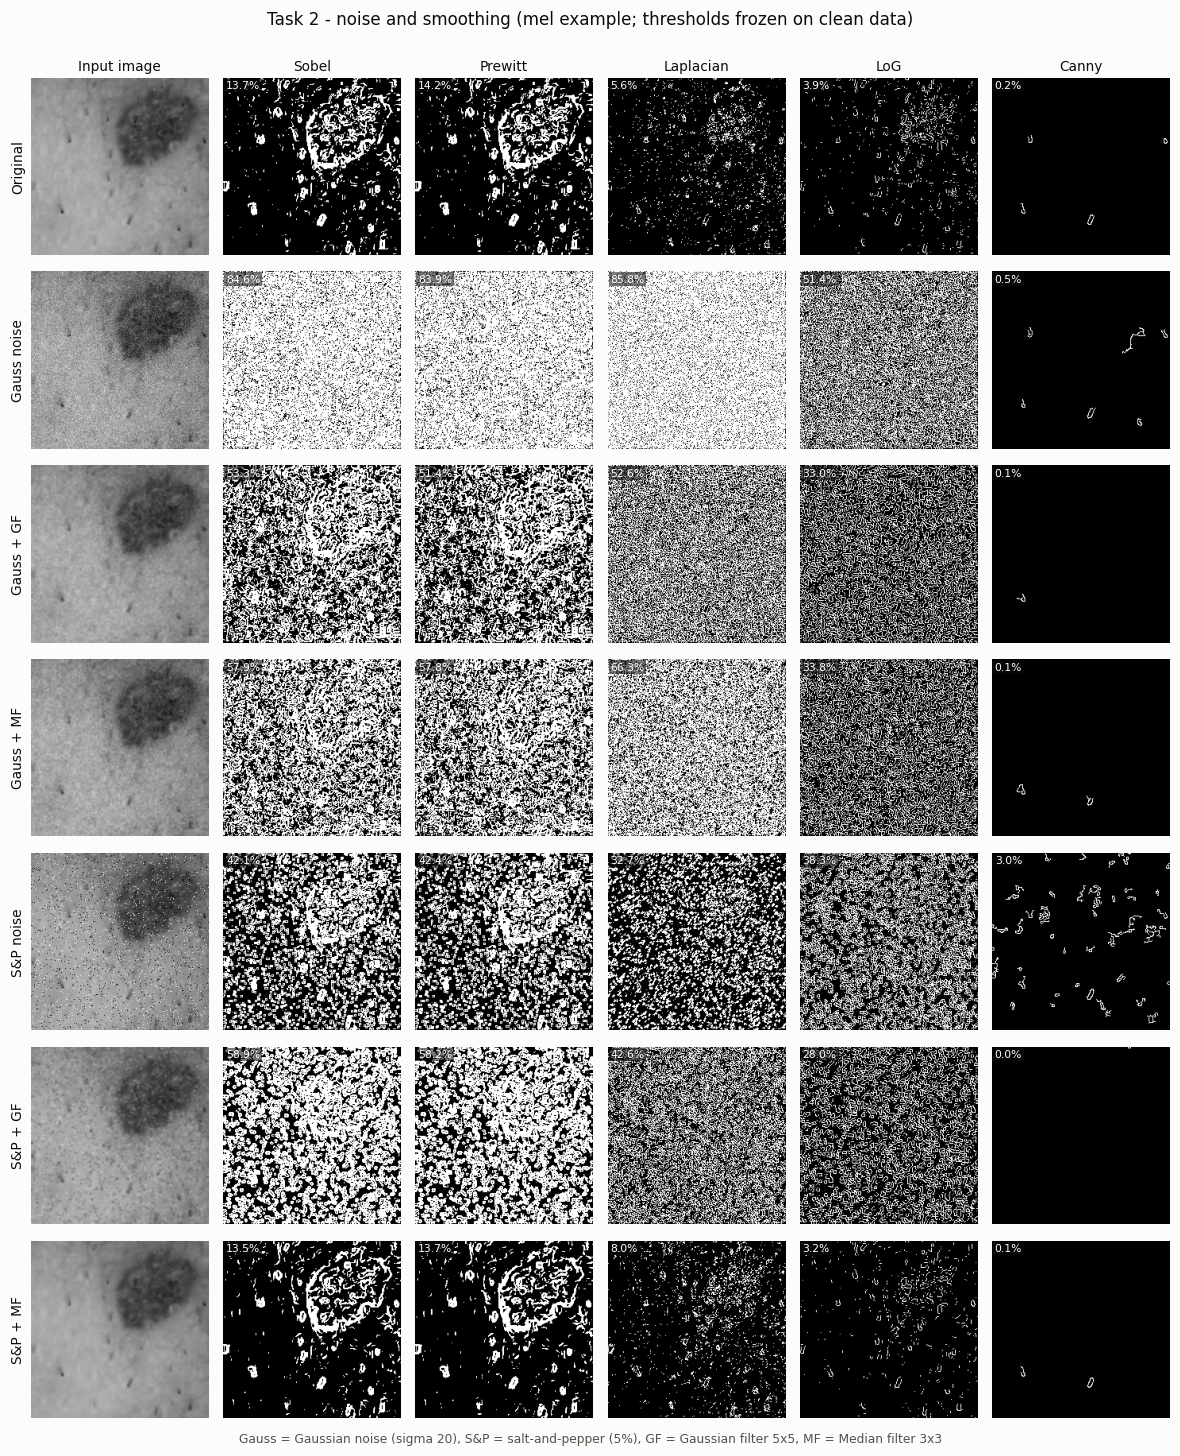

In [12]:
# Noisy and filtered inputs (first column) and every detector's edge map, for one example image.
ex = EXAMPLES[0]
clean = gray_u8(X["test"][ex])
thr = pipeline_thresholds(clean)

fig, axes = plt.subplots(len(CONDITIONS), 1 + len(DETECTORS),
                         figsize=(1.8 * (1 + len(DETECTORS)), 1.85 * len(CONDITIONS)), squeeze=False)
for r, (noise, prep) in enumerate(CONDITIONS):
    g = make_condition(clean, noise, prep, noise_seed(ex, noise))
    axes[r, 0].imshow(g, cmap="gray", vmin=0, vmax=255)
    for c, d in enumerate(DETECTORS, start=1):
        e = edge_map(g, d, thr[(d, prep)])
        axes[r, c].imshow(e, cmap="gray", vmin=0, vmax=1)
        axes[r, c].text(3, 3, "%.1f%%" % (100 * e.mean()), color="#ffffff", fontsize=7, va="top",
                        bbox=dict(facecolor=INK_PRIMARY, alpha=0.55, edgecolor="none", pad=1.2))
    for c, title in enumerate(["Input image"] + list(DETECTORS)):
        bare(axes[r, c])
        if r == 0:
            axes[r, c].set_title(title, fontsize=9, pad=5)
    axes[r, 0].set_ylabel(SHORT[(noise, prep)], fontsize=9, color=INK_PRIMARY)
fig.suptitle("Task 2 - noise and smoothing (%s example; thresholds frozen on clean data)"
             % classes[Y["test"][ex]], fontsize=11, y=1.0)
fig.text(0.5, -0.005, "Gauss = Gaussian noise (sigma %g), S&P = salt-and-pepper (%.0f%%), "
         "GF = Gaussian filter %dx%d, MF = Median filter %dx%d"
         % (cfg.gaussian_noise_sigma, 100 * cfg.sp_amount, cfg.denoise_gaussian_ksize,
            cfg.denoise_gaussian_ksize, cfg.denoise_median_ksize, cfg.denoise_median_ksize),
         ha="center", fontsize=8, color=INK_SECONDARY)
fig.tight_layout()
save_fig(fig, "task2_noise_edges",
         "Figure 3. Original, noisy and filtered inputs (left) and the binary edge maps of every detector. "
         "Label = share of edge pixels.")

In [13]:
# Measure every detector under every condition, averaged over the analysis images.
rows, psnr_rows = [], []
t0 = time.time()
for i in ANALYSIS_IDX:
    clean = gray_u8(X["test"][i])
    thr = pipeline_thresholds(clean)
    ref = {d: edge_map(clean, d, thr[(d, "None")]) for d in DETECTORS}   # the edges to recover
    for noise, prep in CONDITIONS:
        is_ref = (noise, prep) == ("None", "None")
        g = clean if is_ref else make_condition(clean, noise, prep, noise_seed(i, noise))
        if not is_ref:
            psnr_rows.append({"Noise Type": noise, "Preprocessing": prep, "PSNR (dB)": cv2.PSNR(clean, g)})
        for d in DETECTORS:
            e = ref[d] if is_ref else edge_map(g, d, thr[(d, prep)])
            row = {"Edge Detector": d, "Noise Type": noise, "Preprocessing": prep, **structure(e)}
            if not is_ref:
                p, r, f1 = match(e, ref[d])
                row.update({"False edges (%)": 100 * (1 - p), "Missed edges (%)": 100 * (1 - r),
                            "F1 vs clean (%)": 100 * f1})
            rows.append(row)
print("Measured %d edge maps in %.1fs" % (len(rows), time.time() - t0))

KEY = ["Edge Detector", "Noise Type", "Preprocessing"]
T1_FULL = (pd.DataFrame(rows).groupby(KEY).mean(numeric_only=True)
           .reindex(pd.MultiIndex.from_tuples([(d, n, p) for d in DETECTORS for n, p in CONDITIONS], names=KEY)))
clean_px = T1_FULL.xs(("None", "None"), level=["Noise Type", "Preprocessing"])["Edge px (%)"]
T1_FULL["Edge inflation (x)"] = (T1_FULL["Edge px (%)"]
                                 / T1_FULL.index.get_level_values(0).map(clean_px).to_numpy())
T1_COLS = ["Edge px (%)", "Edge inflation (x)", "Fragments", "Mean fragment (px)", "Specks (%)",
           "Thickness (px)", "False edges (%)", "Missed edges (%)", "F1 vs clean (%)"]
T1_FULL = T1_FULL[T1_COLS]

display(T1_FULL.style.format(precision=1, na_rep="-")
        .background_gradient(cmap="Blues", subset=["F1 vs clean (%)"], vmin=0, vmax=100))

Measured 2450 edge maps in 15.3s


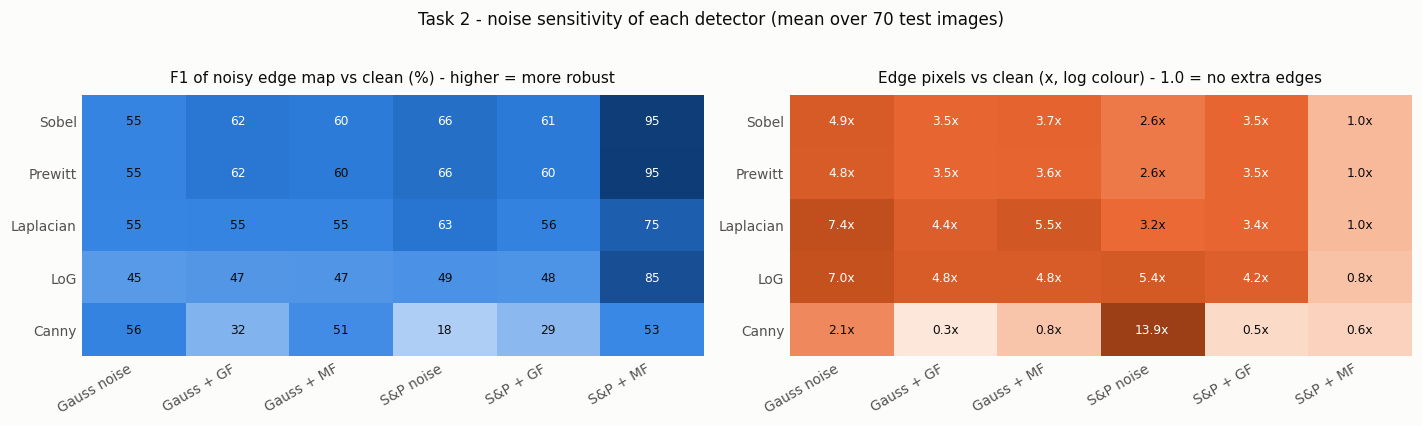

In [14]:
from matplotlib.colors import LogNorm, Normalize

NOISY = [c for c in CONDITIONS if c != ("None", "None")]
f1_grid = np.array([[T1_FULL.loc[(d,) + c, "F1 vs clean (%)"] for c in NOISY] for d in DETECTORS])
inf_grid = np.array([[T1_FULL.loc[(d,) + c, "Edge inflation (x)"] for c in NOISY] for d in DETECTORS])
lo, hi = float(np.nanmin(inf_grid)), float(np.nanmax(inf_grid))

panels = [
    (f1_grid, SEQ_CMAP, Normalize(0, 100), "%.0f",
     "F1 of noisy edge map vs clean (%) - higher = more robust"),
    (inf_grid, cmap_from(SEQ_ORANGE), LogNorm(max(min(lo, 0.9), 0.05), max(hi, 1.1)), "%.1fx",
     "Edge pixels vs clean (x, log colour) - 1.0 = no extra edges"),
]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.7))
for ax, (grid, cmap, norm, fmt, title) in zip(axes, panels):
    ax.imshow(grid, cmap=cmap, norm=norm, aspect="auto")
    ax.set_xticks(range(len(NOISY)))
    ax.set_xticklabels([SHORT[c] for c in NOISY], rotation=30, ha="right")
    ax.set_yticks(range(len(DETECTORS)))
    ax.set_yticklabels(DETECTORS)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    for r in range(grid.shape[0]):
        for c in range(grid.shape[1]):
            v = grid[r, c]
            ax.text(c, r, fmt % v, ha="center", va="center", fontsize=8,
                    color="#ffffff" if norm(v) > 0.6 else INK_PRIMARY)
    ax.set_title(title, fontsize=10, pad=8)
fig.suptitle("Task 2 - noise sensitivity of each detector (mean over %d test images)" % len(ANALYSIS_IDX),
             fontsize=11, y=1.03)
fig.tight_layout()
save_fig(fig, "task2_noise_sensitivity",
         "Figure 4. Left: tolerant F1 between each noisy/filtered edge map and the clean one. "
         "Right: edge-pixel inflation. GF = Gaussian filter, MF = Median filter.")

In [15]:
# How much noise each filter removes, measured on the image itself (dB; higher = closer to clean).
PSNR_TABLE = (pd.DataFrame(psnr_rows).groupby(["Noise Type", "Preprocessing"])["PSNR (dB)"].mean()
              .unstack("Preprocessing").reindex(columns=list(PREPS)))
display(PSNR_TABLE.style.format(precision=2))

Preprocessing,None,Gaussian Filter,Median Filter
Noise Type,,,
Gaussian,22.13,32.30,29.53
Salt & Pepper,18.53,28.74,42.56


### Table 1 — in the task sheet's format
The 11 rows the sheet lists, filled from the measurements above. The full 35-row table stays in the
cell above and goes into the export. The "Noise Sensitivity" label follows F1 vs clean: **Low** ≥ 75%,
**Medium** 50–75%, **High** < 50%.

In [16]:
TABLE1_SPEC = [
    # detector,  input,     noise,           preprocessing (as the sheet words it)
    ("Sobel",     "Original", "None",          "None"),
    ("Sobel",     "Noisy",    "Gaussian",      "None"),
    ("Sobel",     "Noisy",    "Salt & Pepper", "None"),
    ("Sobel",     "Noisy",    "Gaussian",      "Gaussian Filter"),
    ("Sobel",     "Noisy",    "Salt & Pepper", "Median Filter"),
    ("Prewitt",   "Original", "None",          "None"),
    ("Laplacian", "Original", "None",          "None"),
    ("LoG",       "Noisy",    "Gaussian",      "Gaussian Filter"),
    ("Canny",     "Original", "None",          "Built-in smoothing"),
    ("Canny",     "Noisy",    "Gaussian",      "Gaussian Filter"),
    ("Canny",     "Noisy",    "Salt & Pepper", "Median Filter"),
]


def sensitivity_label(f1):
    return "Low" if f1 >= 75 else "Medium" if f1 >= 50 else "High"


def table1_row(det, inp, noise, prep_label):
    s = T1_FULL.loc[(det, noise, "None" if prep_label == "Built-in smoothing" else prep_label)]
    if noise == "None":
        quality = "Clean reference: %.0f-px mean fragment, %.1f px wide" % (s["Mean fragment (px)"], s["Thickness (px)"])
        sens = "-"
    else:
        quality = "F1 %.0f%% vs clean (%.0f%% false, %.0f%% missed)" % (
            s["F1 vs clean (%)"], s["False edges (%)"], s["Missed edges (%)"])
        sens = "%s (%.1fx edge pixels)" % (sensitivity_label(s["F1 vs clean (%)"]), s["Edge inflation (x)"])
    obs = "%.1f%% edge px, %.0f fragments (%.0f%% specks), %.0f-px mean fragment, %.1f px wide" % (
        s["Edge px (%)"], s["Fragments"], s["Specks (%)"], s["Mean fragment (px)"], s["Thickness (px)"])
    return {"Edge Detector": det, "Input Image": inp, "Noise Type": noise, "Preprocessing": prep_label,
            "Edge Quality": quality, "Noise Sensitivity": sens, "Observations": obs}


TABLE1_DOC = pd.DataFrame([table1_row(*spec) for spec in TABLE1_SPEC])
display(TABLE1_DOC.style.hide(axis="index"))

Edge Detector,Input Image,Noise Type,Preprocessing,Edge Quality,Noise Sensitivity,Observations
Sobel,Original,None,None,"Clean reference: 24-px mean fragment, 2.1 px wide",-,"17.0% edge px, 456 fragments (80% specks), 24-px mean fragment, 2.1 px wide"
Sobel,Noisy,Gaussian,None,"F1 55% vs clean (60% false, 0% missed)",Medium (4.9x edge pixels),"83.0% edge px, 62 fragments (31% specks), 30789-px mean fragment, 2.4 px wide"
Sobel,Noisy,Salt & Pepper,None,"F1 66% vs clean (47% false, 0% missed)",Medium (2.6x edge pixels),"43.9% edge px, 396 fragments (52% specks), 60-px mean fragment, 1.9 px wide"
Sobel,Noisy,Gaussian,Gaussian Filter,"F1 62% vs clean (52% false, 1% missed)",Medium (3.5x edge pixels),"59.9% edge px, 258 fragments (82% specks), 3202-px mean fragment, 2.0 px wide"
Sobel,Noisy,Salt & Pepper,Median Filter,"F1 95% vs clean (2% false, 7% missed)",Low (1.0x edge pixels),"16.7% edge px, 303 fragments (74% specks), 35-px mean fragment, 2.5 px wide"
Prewitt,Original,None,None,"Clean reference: 24-px mean fragment, 2.1 px wide",-,"17.2% edge px, 451 fragments (80% specks), 24-px mean fragment, 2.1 px wide"
Laplacian,Original,None,None,"Clean reference: 6-px mean fragment, 1.3 px wide",-,"11.4% edge px, 1235 fragments (91% specks), 6-px mean fragment, 1.3 px wide"
LoG,Noisy,Gaussian,Gaussian Filter,"F1 47% vs clean (68% false, 3% missed)",High (4.8x edge pixels),"34.5% edge px, 556 fragments (79% specks), 212-px mean fragment, 1.2 px wide"
Canny,Original,None,Built-in smoothing,"Clean reference: 28-px mean fragment, 1.4 px wide",-,"0.2% edge px, 1 fragments (0% specks), 28-px mean fragment, 1.4 px wide"
Canny,Noisy,Gaussian,Gaussian Filter,"F1 32% vs clean (4% false, 71% missed)",High (0.3x edge pixels),"0.1% edge px, 0 fragments (0% specks), 19-px mean fragment, 1.3 px wide"


---
## 6 · Task 3 — Canny parameter analysis

The four configurations of Table 2, measured on the same test images. "Edge quality" has three
parts: continuity (mean fragment length), specks (fragments under 10 px) and stability (F1 of the
edges found on a noisy copy against the clean-image edges, with Canny's own smoothing only). Canny
edges are 1 px wide by construction, so thickness does not discriminate here.

In [17]:
rows = []
for i in ANALYSIS_IDX:
    clean = gray_u8(X["test"][i])
    noisy = {n: make_condition(clean, n, "None", noise_seed(i, n)) for n in ("Gaussian", "Salt & Pepper")}
    for name, c in CANNY_CONFIGS.items():
        e = canny(clean, **c)
        row = {"Configuration": name, "Edge px (count)": int(e.sum()), **structure(e)}
        row["F1 under Gaussian noise (%)"] = 100 * match(canny(noisy["Gaussian"], **c), e)[2]
        row["F1 under S&P noise (%)"] = 100 * match(canny(noisy["Salt & Pepper"], **c), e)[2]
        rows.append(row)

T2_FULL = pd.DataFrame(rows).groupby("Configuration", sort=False).mean(numeric_only=True)
T2_FULL.insert(0, "Low", [CANNY_CONFIGS[n]["low"] for n in T2_FULL.index])
T2_FULL.insert(1, "High", [CANNY_CONFIGS[n]["high"] for n in T2_FULL.index])
T2_FULL.insert(2, "Kernel", ["%dx%d" % ((CANNY_CONFIGS[n]["ksize"],) * 2) for n in T2_FULL.index])
display(T2_FULL.style.format(precision=1))

,Low,High,Kernel,Edge px (count),Edge px (%),Fragments,Mean fragment (px),Specks (%),Thickness (px),F1 under Gaussian noise (%),F1 under S&P noise (%)
Configuration,,,,,,,,,,,
Canny-1,30,100,3x3,811.0,1.6,11.9,54.9,3.2,1.3,12.4,15.2
Canny-2,50,150,3x3,235.6,0.5,3.2,34.2,1.6,1.4,25.7,8.8
Canny-3,100,200,3x3,56.3,0.1,1.2,15.6,1.4,1.4,59.7,10.2
Canny-4,50,150,5x5,112.1,0.2,1.4,28.4,0.3,1.4,55.8,18.2


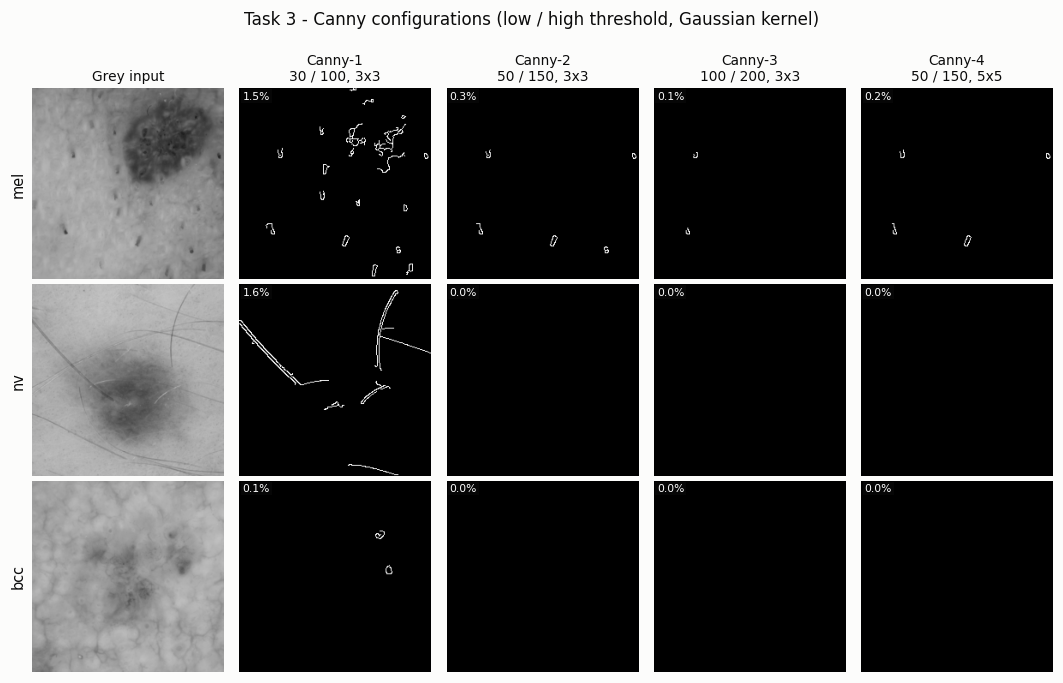

In [18]:
names = list(CANNY_CONFIGS)
fig, axes = plt.subplots(min(3, len(EXAMPLES)), 1 + len(names),
                         figsize=(1.95 * (1 + len(names)), 2.05 * min(3, len(EXAMPLES))), squeeze=False)
for r, i in enumerate(EXAMPLES[:3]):
    g = gray_u8(X["test"][i])
    axes[r, 0].imshow(g, cmap="gray", vmin=0, vmax=255)
    axes[r, 0].set_ylabel(classes[Y["test"][i]], fontsize=9.5, color=INK_PRIMARY)
    for c, name in enumerate(names, start=1):
        e = canny(g, **CANNY_CONFIGS[name])
        axes[r, c].imshow(e, cmap="gray", vmin=0, vmax=1)
        axes[r, c].text(3, 3, "%.1f%%" % (100 * e.mean()), color="#ffffff", fontsize=7, va="top",
                        bbox=dict(facecolor=INK_PRIMARY, alpha=0.55, edgecolor="none", pad=1.2))
    for c in range(1 + len(names)):
        bare(axes[r, c])
        if r == 0:
            if c == 0:
                axes[r, c].set_title("Grey input", fontsize=9, pad=5)
            else:
                k = CANNY_CONFIGS[names[c - 1]]
                axes[r, c].set_title("%s\n%d / %d, %dx%d" % (names[c - 1], k["low"], k["high"], k["ksize"], k["ksize"]),
                                     fontsize=9, pad=5)
fig.suptitle("Task 3 - Canny configurations (low / high threshold, Gaussian kernel)", fontsize=11, y=1.0)
fig.tight_layout()
save_fig(fig, "task3_canny_configs", "Figure 5. The four Canny configurations of Table 2. Label = share of edge pixels.")

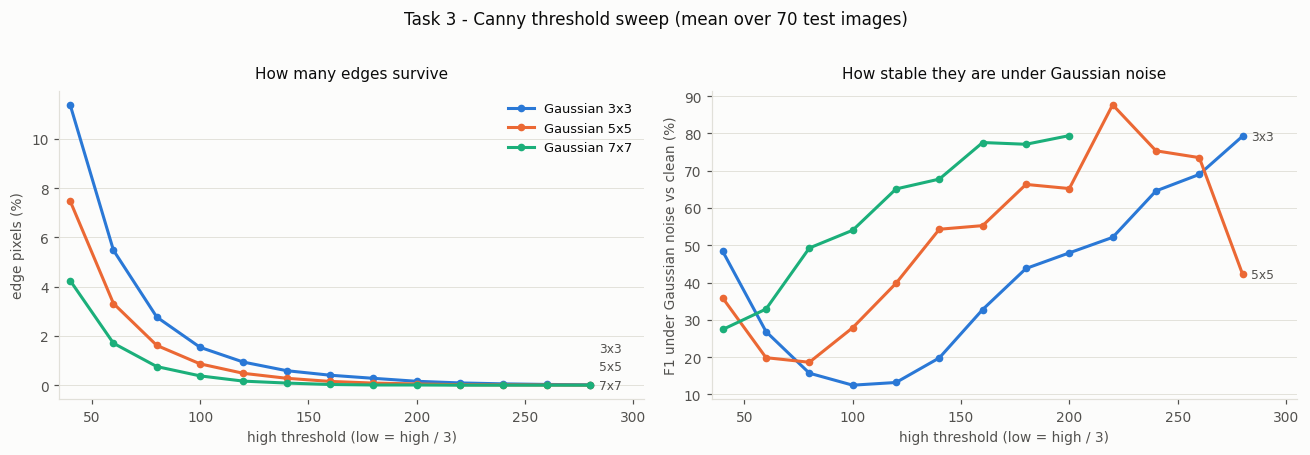

In [19]:
# Threshold sweep: how the number of edges and their stability move with the thresholds.
HIGHS = np.arange(40, 281, 20)
KSIZES = (3, 5, 7)
pairs = []
for i in ANALYSIS_IDX:
    clean = gray_u8(X["test"][i])
    pairs.append((clean, make_condition(clean, "Gaussian", "None", noise_seed(i, "Gaussian"))))

SWEEP = {k: {"density": [], "f1": []} for k in KSIZES}
for k in KSIZES:
    for h in HIGHS:
        lo_, h_ = int(round(h / 3)), int(h)
        dens, f1s = [], []
        for clean, noisy in pairs:
            e = canny(clean, lo_, h_, k)
            dens.append(100 * e.mean())
            f1s.append(100 * match(canny(noisy, lo_, h_, k), e)[2])
        SWEEP[k]["density"].append(float(np.mean(dens)))
        SWEEP[k]["f1"].append(float(np.nanmean(f1s)) if not np.all(np.isnan(f1s)) else np.nan)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, key, ylabel in ((axes[0], "density", "edge pixels (%)"),
                        (axes[1], "f1", "F1 under Gaussian noise vs clean (%)")):
    for j, k in enumerate(KSIZES):
        ax.plot(HIGHS, SWEEP[k][key], color=CATEGORICAL[j], linewidth=2, marker="o", markersize=4,
                label="Gaussian %dx%d" % (k, k))
    label_line_ends(ax, HIGHS[-1] + 4, [SWEEP[k][key][-1] for k in KSIZES], ["%dx%d" % (k, k) for k in KSIZES])
    ax.set_xlabel("high threshold (low = high / 3)")
    ax.set_ylabel(ylabel)
    ax.set_xlim(HIGHS[0] - 5, HIGHS[-1] + 25)
    ax.yaxis.grid(True, linewidth=0.6)
    ax.set_axisbelow(True)
axes[0].legend(frameon=False, fontsize=8.5)
axes[0].set_title("How many edges survive", fontsize=10, pad=8)
axes[1].set_title("How stable they are under Gaussian noise", fontsize=10, pad=8)
fig.suptitle("Task 3 - Canny threshold sweep (mean over %d test images)" % len(pairs), fontsize=11, y=1.02)
fig.tight_layout()
save_fig(fig, "task3_canny_sweep",
         "Figure 6. Canny threshold sweep at a fixed 1:3 low:high ratio for three Gaussian kernel sizes.")

---
## 7 · Choosing the edge representation for classification (Tasks 1–3 → 4)

Task 4 wants "the best edge detection configuration". Tasks 1–3 judge edges by how they *look*;
Task 4 needs edges that are *useful to a classifier*. So the candidates are compared on what they are
about to be used for. This is a quick, cheap probe on the **validation** split: frozen EfficientNet-B0
features and a logistic regression. The test set is never touched.

**Candidates:**
- the graded responses of Sobel, Prewitt, Laplacian and LoG ($\lvert\cdot\rvert$, 99th-percentile
  scaled — the same recipe as Lab 02's Sobel);
- the four binary Canny maps of Table 2.

Raw and Median 3×3 are scored alongside as **references only**; they show how much any edge map
gives up. The winner becomes Set C, unless `cfg.setC_override` names another candidate.

In [20]:
TORCHVISION_NAME = {"EfficientNet-B0": "efficientnet_b0", "ResNet18": "resnet18", "ResNet50": "resnet50"}
MEAN_T = torch.tensor(IMAGENET_MEAN, device=device).view(1, 3, 1, 1)
STD_T = torch.tensor(IMAGENET_STD, device=device).view(1, 3, 1, 1)


def build_model(name, n_classes=None):
    """ImageNet-pretrained torchvision model; n_classes=None gives a penultimate-feature extractor."""
    model = getattr(torchvision.models, TORCHVISION_NAME[name])(weights="DEFAULT")
    if name.startswith("ResNet"):
        dim = model.fc.in_features
        model.fc = nn.Linear(dim, n_classes) if n_classes else nn.Identity()
    else:
        dim = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(dim, n_classes) if n_classes else nn.Identity()
    return model.to(device).to(memory_format=torch.channels_last), dim


def to_input(x_nhwc):
    """uint8 [B, H, W, 3] -> ImageNet-normalised float [B, 3, H, W] on the device (channels-last)."""
    x = torch.from_numpy(np.ascontiguousarray(x_nhwc)).to(device, non_blocking=True)
    x = x.permute(0, 3, 1, 2).float().div_(255.0)
    return ((x - MEAN_T) / STD_T).contiguous(memory_format=torch.channels_last)


@torch.no_grad()
def extract_features(model, Xs):
    model.eval()
    out = []
    for i in range(0, len(Xs), cfg.feat_batch_size):
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            f = model(to_input(Xs[i:i + cfg.feat_batch_size]))
        out.append(f.float().cpu())
    return torch.cat(out).numpy()


def median_image(rgb):
    """Set B: Lab 02's best filter, a 3x3 median on every colour channel."""
    return cv2.medianBlur(rgb, cfg.denoise_median_ksize)


def edge_image(rgb, name):
    """A Set C candidate: one edge map, replicated to 3 channels for the ImageNet CNNs."""
    g = gray_u8(rgb)
    if name in CANNY_CONFIGS:
        e = canny(g, **CANNY_CONFIGS[name]).astype(np.uint8) * 255
    else:
        r = np.abs(response(g, name))
        e = np.clip(r * (255.0 / max(float(np.percentile(r, 99)), 1e-6)), 0, 255).astype(np.uint8)
    return np.repeat(e[:, :, None], 3, axis=2)


def represent(Xs, name):
    """A whole split in representation `name`: "Raw", "Median 3x3" or an edge candidate."""
    if name == "Raw":
        return Xs
    fn = median_image if name == "Median 3x3" else (lambda rgb: edge_image(rgb, name))
    out = np.empty_like(Xs)

    def work(i):
        out[i] = fn(Xs[i])

    with ThreadPoolExecutor(max_workers=cfg.decode_workers) as ex:
        list(ex.map(work, range(len(Xs))))
    return out

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

EDGE_CANDIDATES = ["Sobel", "Prewitt", "Laplacian", "LoG"] + list(CANNY_CONFIGS)
REFERENCES = ["Raw", "Median 3x3"]

feat_model, FEAT_DIM = build_model(cfg.feature_backbone)
extract_features(feat_model, X["train"][:cfg.feat_batch_size])     # warm-up (cuDNN autotuning)

banner("SET C SCREENING - frozen %s (%d-d features) + logistic regression, VALIDATION split"
       % (cfg.feature_backbone, FEAT_DIM))
screen_rows = []
for rep in REFERENCES + EDGE_CANDIDATES:
    t0 = time.time()
    f_tr = extract_features(feat_model, represent(X["train"], rep))
    f_va = extract_features(feat_model, represent(X["val"], rep))
    probe = make_pipeline(StandardScaler(),
                          LogisticRegression(C=0.1, max_iter=3000, class_weight="balanced"))
    probe.fit(f_tr, Y["train"])
    pred = probe.predict(f_va)
    screen_rows.append({
        "Representation": rep,
        "Role": "reference" if rep in REFERENCES else "edge candidate",
        "Val Macro-F1 (%)": 100 * f1_score(Y["val"], pred, average="macro", labels=LABELS, zero_division=0),
        "Val Balanced Acc (%)": 100 * balanced_accuracy_score(Y["val"], pred),
        "Val Accuracy (%)": 100 * accuracy_score(Y["val"], pred),
    })
    print("  %-11s val macro-F1 %5.1f%%   (%.1fs)" % (rep, screen_rows[-1]["Val Macro-F1 (%)"], time.time() - t0))

SCREEN_DF = pd.DataFrame(screen_rows)
ranked = (SCREEN_DF[SCREEN_DF["Role"] == "edge candidate"]
          .sort_values("Val Macro-F1 (%)", ascending=False)["Representation"].tolist())
SET_C = cfg.setC_override or ranked[0]
BEST_CANNY = [r for r in ranked if r in CANNY_CONFIGS][0]
print("\nBest edge representation (Set C): %s%s" % (SET_C, "  [override]" if cfg.setC_override else ""))
print("Best Canny configuration        : %s" % BEST_CANNY)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 124MB/s] 



SET C SCREENING - frozen EfficientNet-B0 (1280-d features) + logistic regression, VALIDATION split
  Raw         val macro-F1  58.6%   (28.2s)
  Median 3x3  val macro-F1  56.8%   (5.1s)
  Sobel       val macro-F1  46.1%   (10.0s)
  Prewitt     val macro-F1  46.1%   (10.8s)
  Laplacian   val macro-F1  30.4%   (9.2s)
  LoG         val macro-F1  38.7%   (10.3s)
  Canny-1     val macro-F1  29.0%   (10.2s)
  Canny-2     val macro-F1  21.9%   (10.7s)
  Canny-3     val macro-F1  15.3%   (8.3s)
  Canny-4     val macro-F1  17.3%   (9.8s)

Best edge representation (Set C): Sobel
Best Canny configuration        : Canny-1


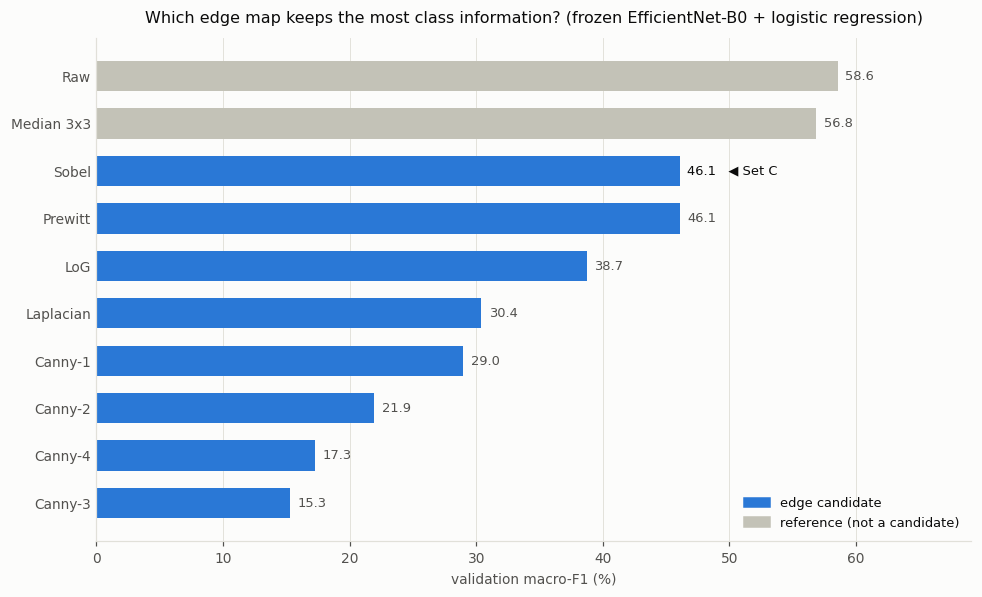

In [22]:
from matplotlib.patches import Patch

sd = SCREEN_DF.sort_values("Val Macro-F1 (%)").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 0.42 * len(sd) + 1.3))
ax.barh(range(len(sd)), sd["Val Macro-F1 (%)"], height=0.64,
        color=[REFERENCE_C if role == "reference" else CATEGORICAL[0] for role in sd["Role"]])
for y, (rep, v) in enumerate(zip(sd["Representation"], sd["Val Macro-F1 (%)"])):
    ax.text(v + 0.6, y, "%.1f%s" % (v, "   ◀ Set C" if rep == SET_C else ""), va="center",
            fontsize=8.5, color=INK_PRIMARY if rep == SET_C else INK_SECONDARY)
ax.set_yticks(range(len(sd)))
ax.set_yticklabels(sd["Representation"])
ax.set_xlim(0, sd["Val Macro-F1 (%)"].max() * 1.18)
ax.set_xlabel("validation macro-F1 (%)")
ax.xaxis.grid(True, linewidth=0.6)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.legend(handles=[Patch(color=CATEGORICAL[0], label="edge candidate"),
                   Patch(color=REFERENCE_C, label="reference (not a candidate)")],
          frameon=False, fontsize=8.5, loc="lower right")
ax.set_title("Which edge map keeps the most class information? (frozen %s + logistic regression)"
             % cfg.feature_backbone, fontsize=10.5, pad=10)
fig.tight_layout()
save_fig(fig, "task4_setC_screening",
         "Figure 7. Validation macro-F1 of each edge representation (frozen %s features + logistic "
         "regression). The best edge candidate becomes Set C." % cfg.feature_backbone)

### Table 2 — in the task sheet's format
The observation column adds each configuration's validation score from the screening above, so the
"most useful configuration" is chosen on data rather than by eye.

In [23]:
val_f1_of = SCREEN_DF.set_index("Representation")["Val Macro-F1 (%)"]


def table2_row(name):
    s, c = T2_FULL.loc[name], CANNY_CONFIGS[name]
    return {
        "Configuration": name,
        "Low Threshold": c["low"],
        "High Threshold": c["high"],
        "Kernel Size": "%dx%d" % (c["ksize"], c["ksize"]),
        "Edge Quality": "%.0f-px mean fragment, %.0f%% specks; F1 under noise %.0f%% / %.0f%% (Gaussian / S&P)"
                        % (s["Mean fragment (px)"], s["Specks (%)"], s["F1 under Gaussian noise (%)"],
                           s["F1 under S&P noise (%)"]),
        "Number of Detected Edges": "%.0f edge px (%.1f%%) in %.0f fragments"
                                    % (s["Edge px (count)"], s["Edge px (%)"], s["Fragments"]),
        "Observation": "val macro-F1 as a classifier input: %.1f%%%s"
                       % (val_f1_of[name], " - best Canny configuration" if name == BEST_CANNY else ""),
    }


TABLE2_DOC = pd.DataFrame([table2_row(n) for n in CANNY_CONFIGS])
display(TABLE2_DOC.style.hide(axis="index"))

Configuration,Low Threshold,High Threshold,Kernel Size,Edge Quality,Number of Detected Edges,Observation
Canny-1,30,100,3x3,"55-px mean fragment, 3% specks; F1 under noise 12% / 15% (Gaussian / S&P)",811 edge px (1.6%) in 12 fragments,val macro-F1 as a classifier input: 29.0% - best Canny configuration
Canny-2,50,150,3x3,"34-px mean fragment, 2% specks; F1 under noise 26% / 9% (Gaussian / S&P)",236 edge px (0.5%) in 3 fragments,val macro-F1 as a classifier input: 21.9%
Canny-3,100,200,3x3,"16-px mean fragment, 1% specks; F1 under noise 60% / 10% (Gaussian / S&P)",56 edge px (0.1%) in 1 fragments,val macro-F1 as a classifier input: 15.3%
Canny-4,50,150,5x5,"28-px mean fragment, 0% specks; F1 under noise 56% / 18% (Gaussian / S&P)",112 edge px (0.2%) in 1 fragments,val macro-F1 as a classifier input: 17.3%


---
## 8 · Task 4 — The three input sets

| Set | Source | Built by |
|---|---|---|
| **A · Raw** | Lab 01 | the decoded images, untouched |
| **B · Filtered** | Lab 02 | 3×3 Median on every colour channel. This was Lab 02's best filter: +2.9 macro-F1 on average, and it never cost more than 0.4 points on any backbone |
| **C · Edge** | Lab 03 | the Section 7 winner, replicated to 3 channels |

All three share Lab 02's train / validation / test split, image for image.

A · Raw            train (1969, 224, 224, 3)  val (524, 224, 224, 3)  test (525, 224, 224, 3)
B · Median 3x3     train (1969, 224, 224, 3)  val (524, 224, 224, 3)  test (525, 224, 224, 3)
C · Sobel edges    train (1969, 224, 224, 3)  val (524, 224, 224, 3)  test (525, 224, 224, 3)


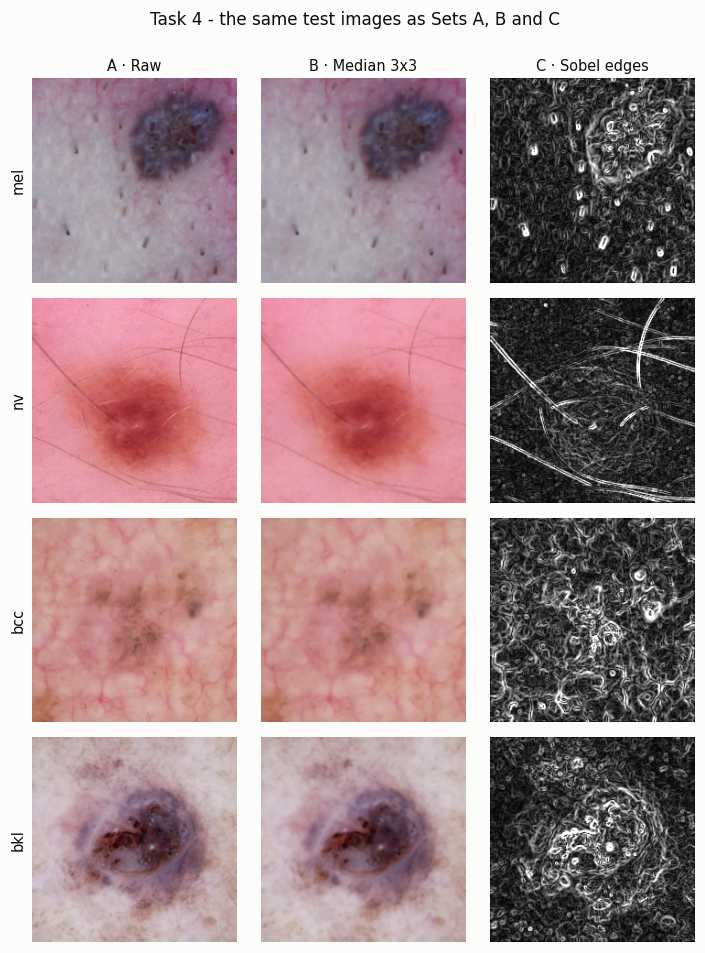

In [24]:
SETS = {
    "Raw":      {s: X[s] for s in X},
    "Filtered": {s: represent(X[s], "Median 3x3") for s in X},
    "Edge":     {s: represent(X[s], SET_C) for s in X},
}
SET_ORDER = list(SETS)
SET_LABEL = {"Raw": "A · Raw", "Filtered": "B · Median 3x3", "Edge": "C · %s edges" % SET_C}
for s in SET_ORDER:
    print("%-18s train %s  val %s  test %s" % (SET_LABEL[s], SETS[s]["train"].shape,
                                              SETS[s]["val"].shape, SETS[s]["test"].shape))

fig, axes = plt.subplots(len(EXAMPLES), 3, figsize=(6.6, 2.15 * len(EXAMPLES)), squeeze=False)
for r, i in enumerate(EXAMPLES):
    for c, s in enumerate(SET_ORDER):
        axes[r, c].imshow(SETS[s]["test"][i])
        bare(axes[r, c])
        if r == 0:
            axes[r, c].set_title(SET_LABEL[s], fontsize=9.5, pad=5)
    axes[r, 0].set_ylabel(classes[Y["test"][i]], fontsize=9.5, color=INK_PRIMARY)
fig.suptitle("Task 4 - the same test images as Sets A, B and C", fontsize=11, y=1.0)
fig.tight_layout()
save_fig(fig, "task4_sets", "Figure 8. The three input representations of the same test images.")

---
## 9 · Training — SVM, Random Forest and KNN on frozen CNN features

Each image is passed once through the frozen ImageNet EfficientNet-B0 (Lab 01 and Lab 02's best
backbone), giving a 1280-d feature vector. The three classical classifiers are trained on those
features. Their hyperparameters are picked on validation macro-F1 from small grids: SVM `C`,
Random Forest `max_features`, KNN `k` and distance metric.

**Timing definitions**, identical for every set:
- **Training time** = extracting the training-set features + fitting the chosen classifier.
- **Inference time** = (extracting the test features + predicting) ÷ number of test images, in ms
  per image. The extraction runs in batches on the GPU.

In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, roc_auc_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC


def macro_f1(y, pred):
    return f1_score(y, pred, average="macro", labels=LABELS, zero_division=0)


def macro_ovr_auc(y, scores):
    """Macro one-vs-rest AUC over the classes present in y."""
    aucs = []
    for c in LABELS:
        b = (y == c).astype(int)
        if 0 < b.sum() < len(b):
            aucs.append(roc_auc_score(b, scores[:, c]))
    return float(np.mean(aucs)) if aucs else float("nan")


def compute_metrics(y, pred, scores):
    """Precision / recall / F1 are macro-averaged, so the 115-image `df` class counts as much as `nv`."""
    p, r, f1, _ = precision_recall_fscore_support(y, pred, average="macro", labels=LABELS, zero_division=0)
    return {
        "Accuracy (%)": 100 * accuracy_score(y, pred),
        "Precision (%)": 100 * p,
        "Recall (%)": 100 * r,
        "F1-Score (%)": 100 * f1,
        "Balanced Acc (%)": 100 * balanced_accuracy_score(y, pred),
        "AUC (%)": 100 * macro_ovr_auc(y, scores),
        "Weighted-F1 (%)": 100 * f1_score(y, pred, average="weighted", labels=LABELS, zero_division=0),
    }


ROWS, RUNS = [], {}     # one row per (model, set) for Table 3; RUNS keeps predictions and curves


def record(model, set_name, pred, scores, train_s, infer_ms, val_f1, params, history=None):
    m = compute_metrics(Y["test"], pred, scores)
    ROWS.append({"Model": model, "Set": set_name, **m, "Training Time (s)": train_s,
                 "Inference Time (ms)": infer_ms, "Val Macro-F1 (%)": 100 * val_f1,
                 "Hyperparameters": params})
    RUNS[(model, set_name)] = {"pred": np.asarray(pred), "scores": scores, "history": history}
    pd.DataFrame(ROWS).to_csv(Path(cfg.out_dir) / "table3_partial.csv", index=False)  # survives a disconnect
    print("    %-26s %-9s acc %5.1f%%  macro-F1 %5.1f%%  bal-acc %5.1f%%  train %6.1fs  infer %6.2f ms/img"
          % (model, set_name, m["Accuracy (%)"], m["F1-Score (%)"], m["Balanced Acc (%)"], train_s, infer_ms))


CLASSIC = {
    # name: (constructor, validation grid)
    "SVM": (lambda **p: SVC(kernel="rbf", gamma="scale", class_weight="balanced", **p),
            [{"C": c} for c in (0.3, 1.0, 3.0, 10.0)]),
    "Random Forest": (lambda **p: RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                                        n_jobs=-1, random_state=cfg.seed, **p),
                      [{"max_features": m} for m in ("sqrt", "log2")]),
    "KNN": (lambda **p: KNeighborsClassifier(weights="distance", n_jobs=-1, **p),
            [{"n_neighbors": k, "metric": m} for k in (5, 9, 15, 25) for m in ("euclidean", "cosine")]),
}


def timed_features(Xs):
    cuda_sync()
    t0 = time.perf_counter()
    f = extract_features(feat_model, Xs)
    cuda_sync()
    return f, time.perf_counter() - t0


def class_scores(clf, feats):
    """Per-class scores for the AUC: probabilities where available, SVM decision values otherwise."""
    return clf.predict_proba(feats) if hasattr(clf, "predict_proba") else clf.decision_function(feats)


banner("SVM / RANDOM FOREST / KNN on frozen %s features" % cfg.feature_backbone)
for set_name in SET_ORDER:
    S = SETS[set_name]
    f_tr, t_ftr = timed_features(S["train"])
    f_va, _ = timed_features(S["val"])
    f_te, t_fte = timed_features(S["test"])
    print("\n%s   (features: train %.1fs, test %.1fs)" % (SET_LABEL[set_name], t_ftr, t_fte))
    for mname, (make, grid) in CLASSIC.items():
        best = None
        for params in grid:
            clf = make_pipeline(StandardScaler(), make(**params))
            t0 = time.perf_counter()
            clf.fit(f_tr, Y["train"])
            t_fit = time.perf_counter() - t0
            vf1 = macro_f1(Y["val"], clf.predict(f_va))
            if best is None or vf1 > best[0]:
                best = (vf1, params, clf, t_fit)
        vf1, params, clf, t_fit = best
        t0 = time.perf_counter()
        pred = clf.predict(f_te)
        t_pred = time.perf_counter() - t0
        record(mname, set_name, pred, class_scores(clf, f_te), t_ftr + t_fit,
               1000 * (t_fte + t_pred) / len(f_te), vf1, str(params))

del feat_model
free_memory()


SVM / RANDOM FOREST / KNN on frozen EfficientNet-B0 features

A · Raw   (features: train 1.2s, test 10.7s)
    SVM                        Raw       acc  61.9%  macro-F1  60.6%  bal-acc  58.4%  train    4.3s  infer  21.99 ms/img
    Random Forest              Raw       acc  57.0%  macro-F1  51.3%  bal-acc  50.0%  train   18.5s  infer  20.62 ms/img
    KNN                        Raw       acc  53.1%  macro-F1  49.3%  bal-acc  49.7%  train    1.2s  infer  20.54 ms/img

B · Median 3x3   (features: train 1.2s, test 0.3s)
    SVM                        Filtered  acc  58.5%  macro-F1  58.6%  bal-acc  56.9%  train    4.3s  infer   2.14 ms/img
    Random Forest              Filtered  acc  55.6%  macro-F1  48.1%  bal-acc  46.7%  train   19.4s  infer   0.80 ms/img
    KNN                        Filtered  acc  52.2%  macro-F1  48.0%  bal-acc  47.2%  train    1.2s  infer   0.73 ms/img

C · Sobel edges   (features: train 1.2s, test 0.3s)
    SVM                        Edge      acc  49.7%  macro-F1

---
## 10 · Training — fine-tuned EfficientNet-B0 and ResNet50

Lab 02's two strongest backbones, fine-tuned **end-to-end** so each network can adapt to whatever
representation it is given. That matters most for edge maps, which look nothing like ImageNet.

**The recipe, identical for both models and all three sets:**
- ImageNet initialisation, all layers trainable;
- AdamW (lr 3e-4, weight decay 1e-4) with a one-cycle schedule (10% warm-up, cosine decay);
- batch 32, 12 epochs, mixed precision, class-weighted cross-entropy;
- **augmentation**: random horizontal and vertical flips plus a transpose, i.e. all 8 orientations.
  A lesion has no "up", and an edge map rotates with its image, so this is fair to every set;
- the checkpoint with the best **validation** macro-F1 is the one evaluated on test.

**Training time** is the full training loop, including the per-epoch validation passes used to pick the
checkpoint. **Inference time** is a batched test pass (batch 128, after a warm-up) ÷ number of images.

In [26]:
def augment(x):
    """Per-image random flips + transpose -> all 8 orientations of a square image."""
    b = x.shape[0]
    for op in (lambda t: t.flip(3), lambda t: t.flip(2), lambda t: t.transpose(2, 3)):
        mask = torch.rand(b, 1, 1, 1, device=x.device) < 0.5
        x = torch.where(mask, op(x), x)
    return x.contiguous(memory_format=torch.channels_last)


@torch.no_grad()
def predict_probs(model, Xs):
    model.eval()
    out = []
    for i in range(0, len(Xs), cfg.eval_batch_size):
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(to_input(Xs[i:i + cfg.eval_batch_size]))
        out.append(torch.softmax(logits.float(), dim=1).cpu())
    return torch.cat(out).numpy()


def finetune(name, S):
    """Fine-tune `name` on set S; returns (model at best val epoch, history, train seconds, best val F1)."""
    set_seed(cfg.seed)
    model, _ = build_model(name, N_CLASSES)
    Xtr, ytr = S["train"], torch.from_numpy(Y["train"])
    n, bs = len(Xtr), cfg.ft_batch_size
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.ft_lr, weight_decay=cfg.ft_weight_decay)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg.ft_lr, pct_start=0.1,
                                                total_steps=cfg.ft_epochs * math.ceil(n / bs))
    scaler = torch.amp.GradScaler(device.type, enabled=USE_AMP)
    counts = np.bincount(Y["train"], minlength=N_CLASSES).clip(min=1)
    weights = torch.tensor(counts.sum() / (N_CLASSES * counts), dtype=torch.float32, device=device)
    criterion = nn.CrossEntropyLoss(weight=weights)
    gen = torch.Generator().manual_seed(cfg.seed)

    history = {k: [] for k in ("epoch", "train_loss", "train_acc", "val_loss", "val_acc", "val_f1")}
    best_f1, best_state, best_epoch = -1.0, None, 0
    cuda_sync()
    t0 = time.perf_counter()
    for ep in range(1, cfg.ft_epochs + 1):
        model.train()
        perm = torch.randperm(n, generator=gen)
        run_loss = torch.zeros((), device=device)
        run_correct = torch.zeros((), device=device, dtype=torch.long)
        for i in range(0, n, bs):
            idx = perm[i:i + bs].sort().values           # sorted gathers are faster; order is irrelevant
            xb = augment(to_input(Xtr[idx.numpy()]))
            yb = ytr[idx].to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(xb)
                loss = criterion(logits, yb)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            run_loss += loss.detach().float() * len(idx)
            run_correct += (logits.argmax(1) == yb).sum()

        probs = predict_probs(model, S["val"])
        val_pred = probs.argmax(1)
        val_f1 = macro_f1(Y["val"], val_pred)
        val_loss = float(F.nll_loss(torch.from_numpy(probs).clamp_min(1e-7).log(),
                                    torch.from_numpy(Y["val"]), weight=weights.cpu()))
        history["epoch"].append(ep)
        history["train_loss"].append(float(run_loss) / n)
        history["train_acc"].append(100.0 * float(run_correct) / n)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(100.0 * float((val_pred == Y["val"]).mean()))
        history["val_f1"].append(100.0 * val_f1)
        if val_f1 > best_f1:
            best_f1, best_epoch = val_f1, ep
            best_state = {k: v.detach().to("cpu", copy=True) for k, v in model.state_dict().items()}
        print("      epoch %2d/%d  train loss %.3f acc %5.1f%% | val loss %.3f acc %5.1f%% macro-F1 %5.1f%%%s"
              % (ep, cfg.ft_epochs, history["train_loss"][-1], history["train_acc"][-1], val_loss,
                 history["val_acc"][-1], 100 * val_f1, "  *" if best_epoch == ep else ""))
    cuda_sync()
    train_s = time.perf_counter() - t0
    model.load_state_dict(best_state)
    history["best_epoch"] = best_epoch
    return model, history, train_s, best_f1


def timed_predict(model, Xs):
    predict_probs(model, Xs[:cfg.eval_batch_size])        # warm-up
    cuda_sync()
    t0 = time.perf_counter()
    probs = predict_probs(model, Xs)
    cuda_sync()
    return probs, 1000 * (time.perf_counter() - t0) / len(Xs)

In [27]:
CNN_NAMES = {m: "CNN %d · %s" % (k + 1, m) for k, m in enumerate(cfg.cnn_models)}

banner("FINE-TUNING  -  %d CNNs x %d sets, %d epochs each (* = best validation epoch so far)"
       % (len(cfg.cnn_models), len(SET_ORDER), cfg.ft_epochs))
for mname in cfg.cnn_models:
    for set_name in SET_ORDER:
        print("\n  %s on %s" % (mname, SET_LABEL[set_name]))
        model, hist, t_train, vf1 = finetune(mname, SETS[set_name])
        probs, ms = timed_predict(model, SETS[set_name]["test"])
        record(CNN_NAMES[mname], set_name, probs.argmax(1), probs, t_train, ms, vf1,
               "AdamW lr=%g, %d epochs, batch %d, best epoch %d"
               % (cfg.ft_lr, cfg.ft_epochs, cfg.ft_batch_size, hist["best_epoch"]), hist)
        del model
        free_memory()


FINE-TUNING  -  2 CNNs x 3 sets, 12 epochs each (* = best validation epoch so far)

  EfficientNet-B0 on A · Raw
      epoch  1/12  train loss 1.783 acc  29.9% | val loss 1.205 acc  57.1% macro-F1  55.4%  *
      epoch  2/12  train loss 0.917 acc  65.5% | val loss 0.899 acc  65.5% macro-F1  65.9%  *
      epoch  3/12  train loss 0.601 acc  74.8% | val loss 0.760 acc  69.5% macro-F1  69.7%  *
      epoch  4/12  train loss 0.489 acc  79.0% | val loss 0.814 acc  68.3% macro-F1  68.9%
      epoch  5/12  train loss 0.356 acc  84.4% | val loss 0.726 acc  71.9% macro-F1  71.0%  *
      epoch  6/12  train loss 0.269 acc  88.3% | val loss 0.729 acc  72.1% macro-F1  72.6%  *
      epoch  7/12  train loss 0.257 acc  90.2% | val loss 0.757 acc  75.0% macro-F1  75.0%  *
      epoch  8/12  train loss 0.198 acc  92.0% | val loss 0.725 acc  76.0% macro-F1  76.2%  *
      epoch  9/12  train loss 0.159 acc  93.8% | val loss 0.794 acc  75.0% macro-F1  74.5%
      epoch 10/12  train loss 0.141 acc  94.6%

100%|██████████| 97.8M/97.8M [00:00<00:00, 124MB/s]


      epoch  1/12  train loss 1.752 acc  35.8% | val loss 1.283 acc  51.7% macro-F1  48.1%  *
      epoch  2/12  train loss 0.952 acc  65.9% | val loss 0.960 acc  63.2% macro-F1  64.0%  *
      epoch  3/12  train loss 0.624 acc  73.7% | val loss 0.822 acc  68.7% macro-F1  67.2%  *
      epoch  4/12  train loss 0.461 acc  79.6% | val loss 1.027 acc  63.0% macro-F1  61.5%
      epoch  5/12  train loss 0.357 acc  84.8% | val loss 0.872 acc  72.3% macro-F1  71.3%  *
      epoch  6/12  train loss 0.272 acc  87.5% | val loss 0.945 acc  70.2% macro-F1  69.3%
      epoch  7/12  train loss 0.210 acc  90.9% | val loss 0.991 acc  70.2% macro-F1  69.7%
      epoch  8/12  train loss 0.149 acc  93.2% | val loss 0.944 acc  73.1% macro-F1  72.8%  *
      epoch  9/12  train loss 0.107 acc  95.8% | val loss 0.955 acc  72.7% macro-F1  71.0%
      epoch 10/12  train loss 0.087 acc  96.3% | val loss 0.958 acc  72.1% macro-F1  70.4%
      epoch 11/12  train loss 0.066 acc  97.2% | val loss 0.948 acc  71.9% 

---
## 11 · Task 5 — Classification performance (Table 3)

Precision, recall and F1 are **macro-averaged**. The test set is capped per class, so macro-F1 and
balanced accuracy are the honest headline numbers; plain accuracy is shown because the sheet asks
for it.

In [28]:
MODEL_ORDER = list(CLASSIC) + [CNN_NAMES[m] for m in cfg.cnn_models]
_rank = {**{m: i for i, m in enumerate(MODEL_ORDER)}, **{s: i for i, s in enumerate(SET_ORDER)}}
RESULTS = (pd.DataFrame(ROWS).sort_values(["Model", "Set"], key=lambda col: col.map(_rank))
           .reset_index(drop=True))
R = RESULTS.set_index(["Model", "Set"])
METRIC_COLS = ["Accuracy (%)", "Precision (%)", "Recall (%)", "F1-Score (%)", "Balanced Acc (%)",
               "AUC (%)", "Weighted-F1 (%)", "Training Time (s)", "Inference Time (ms)", "Val Macro-F1 (%)"]

print("Full results (test split):")
display(RESULTS[["Model", "Set"] + METRIC_COLS].style.format(precision=2).hide(axis="index")
        .background_gradient(cmap="Blues", subset=["F1-Score (%)", "Balanced Acc (%)"]))

print("Macro-F1 by model and input set, and the change against Raw (percentage points):")
f1_wide = RESULTS.pivot(index="Model", columns="Set", values="F1-Score (%)").reindex(index=MODEL_ORDER, columns=SET_ORDER)
delta_wide = f1_wide.drop(columns="Raw").sub(f1_wide["Raw"], axis=0).add_prefix("Δ ")
display(pd.concat([f1_wide, delta_wide], axis=1).style.format(precision=2))

Full results (test split):


Model,Set,Accuracy (%),Precision (%),Recall (%),F1-Score (%),Balanced Acc (%),AUC (%),Weighted-F1 (%),Training Time (s),Inference Time (ms),Val Macro-F1 (%)
SVM,Raw,61.90,66.57,58.38,60.58,58.38,87.54,61.78,4.33,21.99,62.33
SVM,Filtered,58.48,62.33,56.90,58.62,56.90,86.62,58.53,4.27,2.14,62.52
SVM,Edge,49.71,45.89,45.93,45.25,45.93,80.00,48.90,4.58,2.29,50.46
Random Forest,Raw,56.95,53.59,50.04,51.25,50.04,87.45,56.03,18.48,20.62,48.97
Random Forest,Filtered,55.62,52.34,46.67,48.09,46.67,86.70,54.63,19.40,0.80,49.05
Random Forest,Edge,47.43,43.32,40.50,40.64,40.50,80.09,45.81,18.13,0.80,46.61
KNN,Raw,53.14,52.06,49.72,49.27,49.72,83.27,52.73,1.22,20.54,50.79
KNN,Filtered,52.19,61.54,47.25,47.98,47.25,84.24,51.80,1.21,0.73,50.69
KNN,Edge,43.24,47.42,39.75,41.08,39.75,74.91,43.53,1.25,0.82,44.65
CNN 1 · EfficientNet-B0,Raw,75.81,76.75,78.32,77.38,78.32,96.51,75.79,150.90,0.60,77.01


Macro-F1 by model and input set, and the change against Raw (percentage points):


Set,Raw,Filtered,Edge,Δ Filtered,Δ Edge
Model,,,,,
SVM,60.58,58.62,45.25,-1.96,-15.34
Random Forest,51.25,48.09,40.64,-3.16,-10.61
KNN,49.27,47.98,41.08,-1.29,-8.20
CNN 1 · EfficientNet-B0,77.38,75.18,52.49,-2.20,-24.89
CNN 2 · ResNet50,77.31,73.23,52.62,-4.08,-24.69


### Table 3 — in the task sheet's format
The sheet has one accuracy column per set but a single Precision / Recall / F1 / time column, so
each of those cells reads **Raw / Filtered / Edge**. SVM, Random Forest and KNN work on frozen
EfficientNet-B0 features, and the two CNN rows are fine-tuned end-to-end. "Accuracy Raw (Lab 1)" is
the raw-image result on this split; Lab 01 itself used a different dataset (ISIC).

In [29]:
TABLE3_NAME = {**{m: m for m in CLASSIC},
               **{CNN_NAMES[m]: "CNN Model %d (%s, fine-tuned)" % (k + 1, m) for k, m in enumerate(cfg.cnn_models)}}


def per_set(model, col, fmt):
    return " / ".join(fmt % R.loc[(model, s), col] for s in SET_ORDER)


TABLE3_DOC = pd.DataFrame([{
    "Model / Classifier": TABLE3_NAME[m],
    "Accuracy Raw (Lab 1)": "%.1f" % R.loc[(m, "Raw"), "Accuracy (%)"],
    "Accuracy Filtered (Lab 2)": "%.1f" % R.loc[(m, "Filtered"), "Accuracy (%)"],
    "Accuracy Edge (Lab 3)": "%.1f" % R.loc[(m, "Edge"), "Accuracy (%)"],
    "Precision": per_set(m, "Precision (%)", "%.1f"),
    "Recall": per_set(m, "Recall (%)", "%.1f"),
    "F1-Score": per_set(m, "F1-Score (%)", "%.1f"),
    "Training Time (s)": per_set(m, "Training Time (s)", "%.1f"),
    "Inference Time (ms)": per_set(m, "Inference Time (ms)", "%.2f"),
} for m in MODEL_ORDER])
display(TABLE3_DOC.style.hide(axis="index"))

Model / Classifier,Accuracy Raw (Lab 1),Accuracy Filtered (Lab 2),Accuracy Edge (Lab 3),Precision,Recall,F1-Score,Training Time (s),Inference Time (ms)
SVM,61.9,58.5,49.7,66.6 / 62.3 / 45.9,58.4 / 56.9 / 45.9,60.6 / 58.6 / 45.2,4.3 / 4.3 / 4.6,21.99 / 2.14 / 2.29
Random Forest,57.0,55.6,47.4,53.6 / 52.3 / 43.3,50.0 / 46.7 / 40.5,51.3 / 48.1 / 40.6,18.5 / 19.4 / 18.1,20.62 / 0.80 / 0.80
KNN,53.1,52.2,43.2,52.1 / 61.5 / 47.4,49.7 / 47.2 / 39.7,49.3 / 48.0 / 41.1,1.2 / 1.2 / 1.2,20.54 / 0.73 / 0.82
"CNN Model 1 (EfficientNet-B0, fine-tuned)",75.8,74.9,56.2,76.7 / 76.1 / 51.3,78.3 / 75.6 / 55.8,77.4 / 75.2 / 52.5,150.9 / 58.0 / 57.9,0.60 / 0.61 / 0.63
"CNN Model 2 (ResNet50, fine-tuned)",76.0,72.4,53.5,76.1 / 72.5 / 50.9,79.0 / 74.8 / 57.1,77.3 / 73.2 / 52.6,91.7 / 82.5 / 82.4,1.56 / 1.11 / 1.10


---
## 12 · Task 6 — Visual comparison

The **best-performing model** is the one with the highest validation macro-F1, averaged over the
three sets. It is chosen on validation, so the test numbers shown for it stay unbiased.

Best-performing model (mean validation macro-F1 over the three sets): CNN 1 · EfficientNet-B0


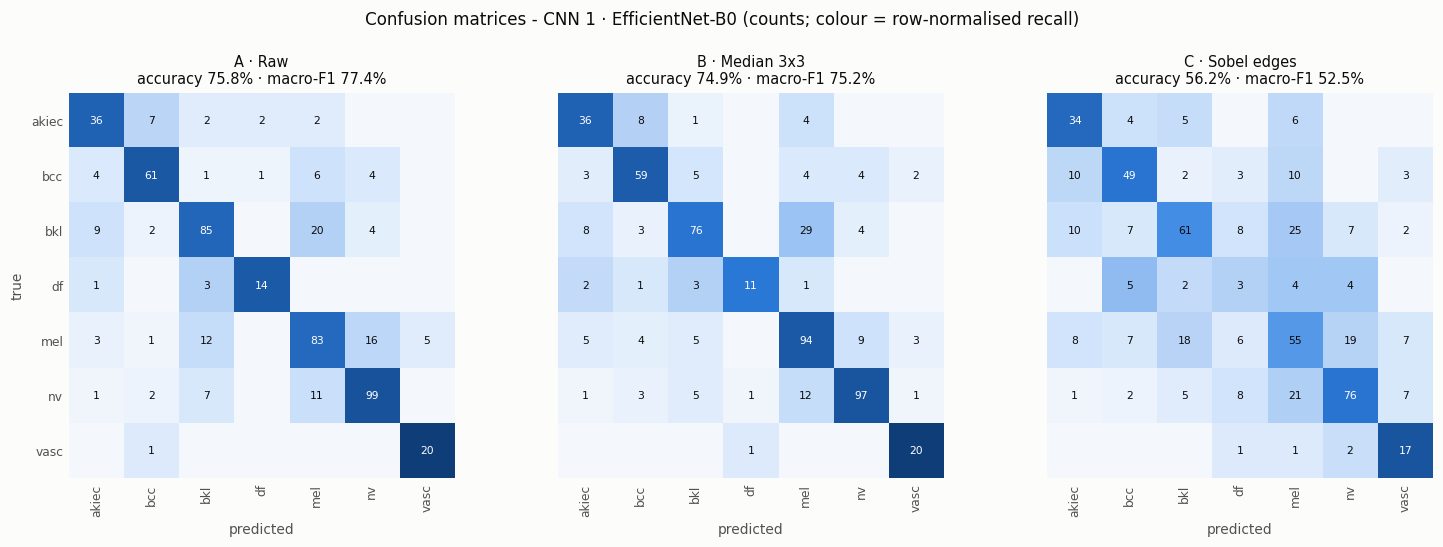

In [30]:
BEST_MODEL = RESULTS.groupby("Model")["Val Macro-F1 (%)"].mean().idxmax()
print("Best-performing model (mean validation macro-F1 over the three sets):", BEST_MODEL)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
cmap = SEQ_CMAP
for k, (ax, s) in enumerate(zip(axes, SET_ORDER)):
    cm = confusion_matrix(Y["test"], RUNS[(BEST_MODEL, s)]["pred"], labels=LABELS)
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)     # row-normalised: classes differ in size
    ax.imshow(cmn, cmap=cmap, vmin=0, vmax=1)
    ax.set_xticks(LABELS)
    ax.set_xticklabels(classes, rotation=90, fontsize=8)
    ax.set_yticks(LABELS)
    ax.set_yticklabels(classes if k == 0 else [], fontsize=8)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    for i in LABELS:
        for j in LABELS:
            if cm[i, j]:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                        color="#ffffff" if cmn[i, j] > 0.55 else INK_PRIMARY)
    ax.set_title("%s\naccuracy %.1f%% · macro-F1 %.1f%%"
                 % (SET_LABEL[s], R.loc[(BEST_MODEL, s), "Accuracy (%)"], R.loc[(BEST_MODEL, s), "F1-Score (%)"]),
                 fontsize=9.5, pad=6)
    ax.set_xlabel("predicted")
axes[0].set_ylabel("true")
fig.suptitle("Confusion matrices - %s (counts; colour = row-normalised recall)" % BEST_MODEL,
             fontsize=11, y=1.03)
fig.tight_layout()
save_fig(fig, "task6_confusion_best",
         "Figure 9. Confusion matrices of the best model (%s) on raw, filtered and edge images." % BEST_MODEL)

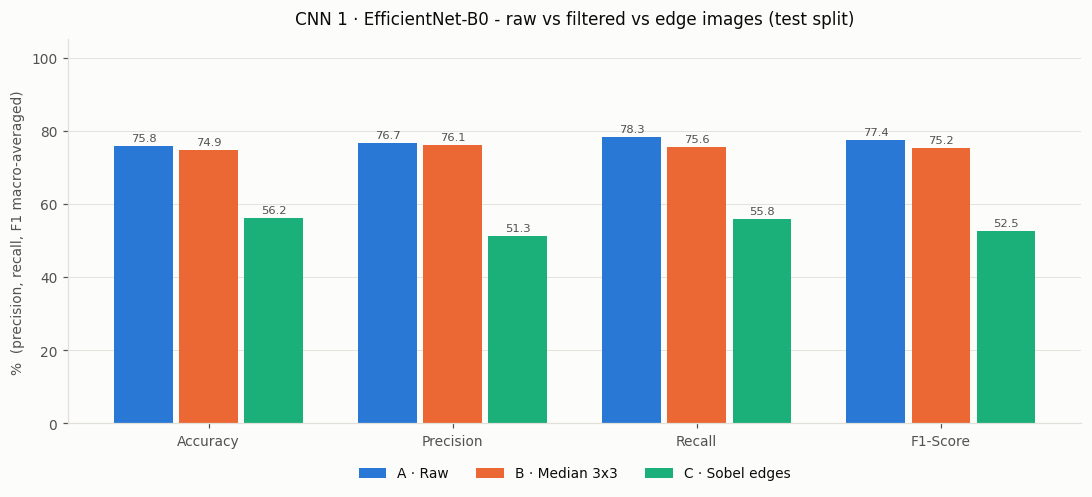

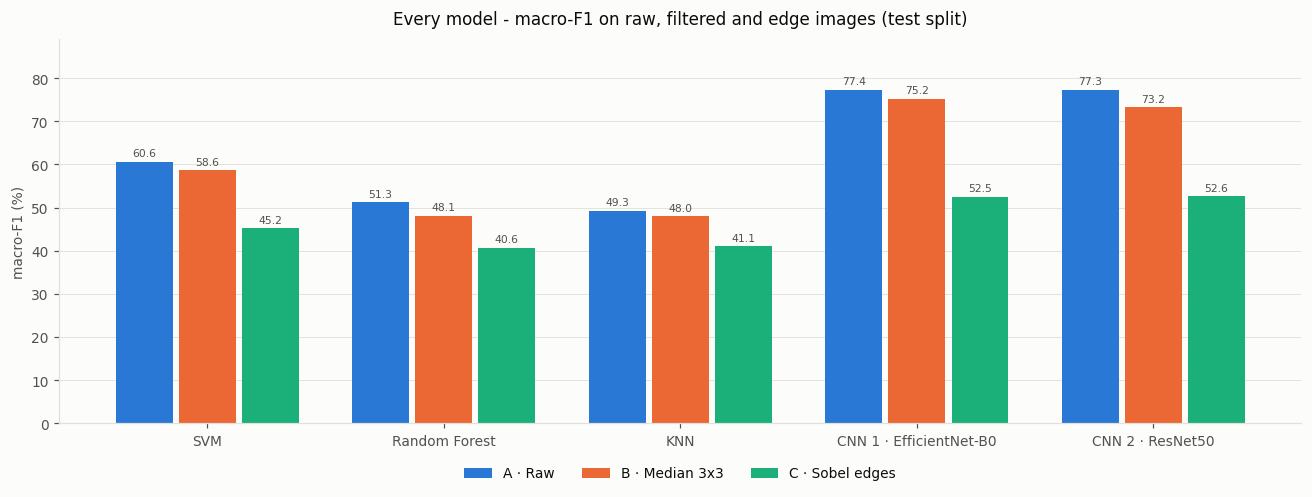

In [31]:
BAR_METRICS = ["Accuracy (%)", "Precision (%)", "Recall (%)", "F1-Score (%)"]


def grouped_bars(ax, groups, value_of, label_fmt="%.1f", fontsize=7.5):
    """Bars grouped by `groups`, one bar per input set, coloured by set."""
    x = np.arange(len(groups))
    w = 0.8 / len(SET_ORDER)
    for k, s in enumerate(SET_ORDER):
        vals = [value_of(g, s) for g in groups]
        pos = x + (k - (len(SET_ORDER) - 1) / 2) * w
        ax.bar(pos, vals, width=w * 0.9, color=SET_COLORS[s], label=SET_LABEL[s])
        for xi, v in zip(pos, vals):
            ax.text(xi, v + 0.8, label_fmt % v, ha="center", va="bottom", fontsize=fontsize, color=INK_SECONDARY)
    ax.set_xticks(x)
    ax.yaxis.grid(True, linewidth=0.6)
    ax.set_axisbelow(True)
    return x


fig, ax = plt.subplots(figsize=(10, 4.6))
x = grouped_bars(ax, BAR_METRICS, lambda m, s: R.loc[(BEST_MODEL, s), m])
ax.set_xticklabels([m.replace(" (%)", "") for m in BAR_METRICS])
ax.set_ylim(0, 105)
ax.set_ylabel("%  (precision, recall, F1 macro-averaged)")
ax.legend(frameon=False, fontsize=9, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.08))
ax.set_title("%s - raw vs filtered vs edge images (test split)" % BEST_MODEL, fontsize=11, pad=10)
fig.tight_layout()
save_fig(fig, "task6_metrics_best",
         "Figure 10. Accuracy, precision, recall and F1 of the best model (%s) on the three input sets." % BEST_MODEL)

fig, ax = plt.subplots(figsize=(12, 4.6))
x = grouped_bars(ax, MODEL_ORDER, lambda m, s: R.loc[(m, s), "F1-Score (%)"], fontsize=7)
ax.set_xticklabels(MODEL_ORDER)
ax.set_ylim(0, max(RESULTS["F1-Score (%)"].max() * 1.15, 10))
ax.set_ylabel("macro-F1 (%)")
ax.legend(frameon=False, fontsize=9, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.08))
ax.set_title("Every model - macro-F1 on raw, filtered and edge images (test split)", fontsize=11, pad=10)
fig.tight_layout()
save_fig(fig, "task6_macro_f1_all_models", "Figure 11. Test macro-F1 of all five classifiers on the three input sets.")

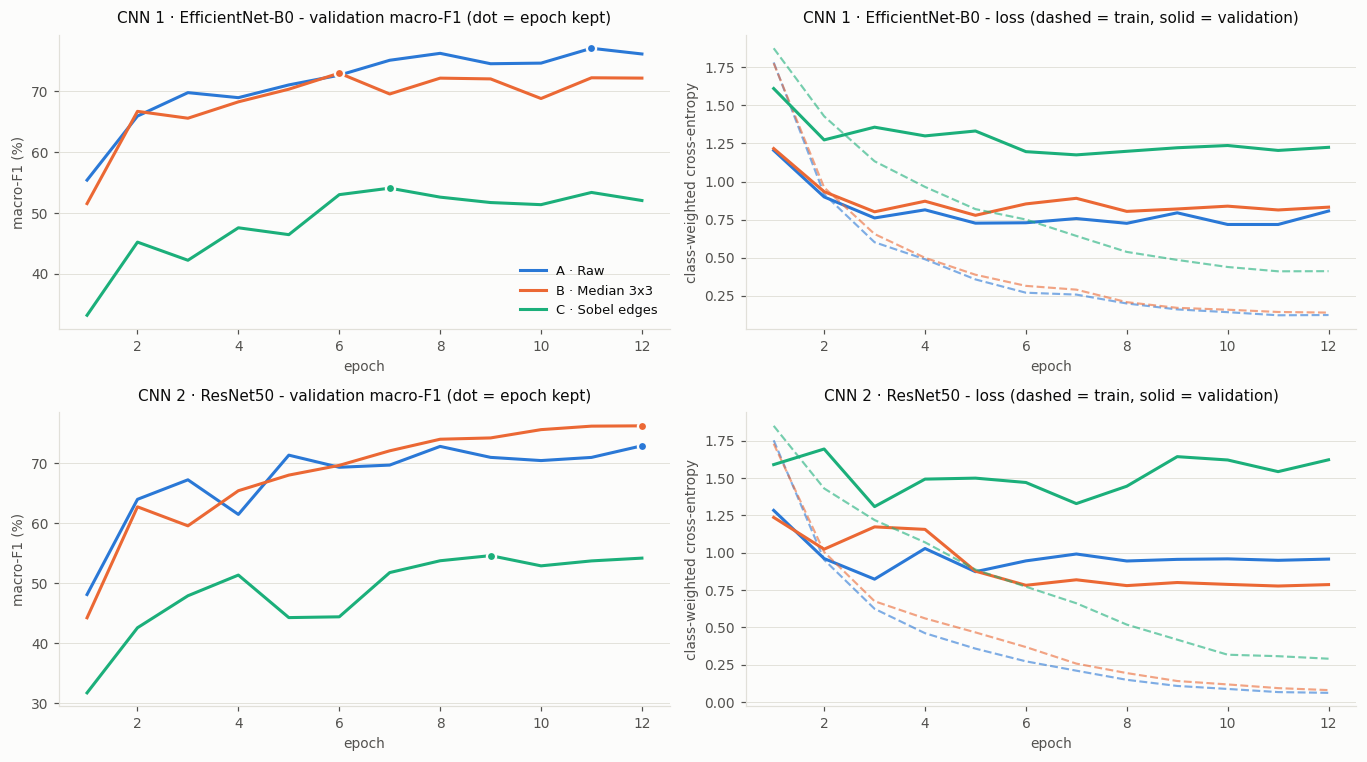

In [32]:
# Fine-tuning curves: one row per CNN, one line per input set.
from matplotlib.ticker import MaxNLocator

cnns = [CNN_NAMES[m] for m in cfg.cnn_models]
fig, axes = plt.subplots(len(cnns), 2, figsize=(12.5, 3.5 * len(cnns)), squeeze=False)
for r, mname in enumerate(cnns):
    for s in SET_ORDER:
        h = RUNS[(mname, s)]["history"]
        axes[r][0].plot(h["epoch"], h["val_f1"], color=SET_COLORS[s], linewidth=2, label=SET_LABEL[s])
        axes[r][0].scatter([h["best_epoch"]], [h["val_f1"][h["best_epoch"] - 1]], s=36, color=SET_COLORS[s],
                           edgecolor=SURFACE, linewidth=1.5, zorder=3)
        axes[r][1].plot(h["epoch"], h["train_loss"], color=SET_COLORS[s], linewidth=1.4, linestyle="--", alpha=0.6)
        axes[r][1].plot(h["epoch"], h["val_loss"], color=SET_COLORS[s], linewidth=2, label=SET_LABEL[s])
    axes[r][0].set_title("%s - validation macro-F1 (dot = epoch kept)" % mname, fontsize=10, pad=8)
    axes[r][1].set_title("%s - loss (dashed = train, solid = validation)" % mname, fontsize=10, pad=8)
    for ax in axes[r]:
        ax.set_xlabel("epoch")
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.yaxis.grid(True, linewidth=0.6)
        ax.set_axisbelow(True)
    axes[r][0].set_ylabel("macro-F1 (%)")
    axes[r][1].set_ylabel("class-weighted cross-entropy")
axes[0][0].legend(frameon=False, fontsize=8.5)
fig.tight_layout()
save_fig(fig, "task6_training_curves", "Figure 12. Fine-tuning curves of both CNNs on the three input sets.")

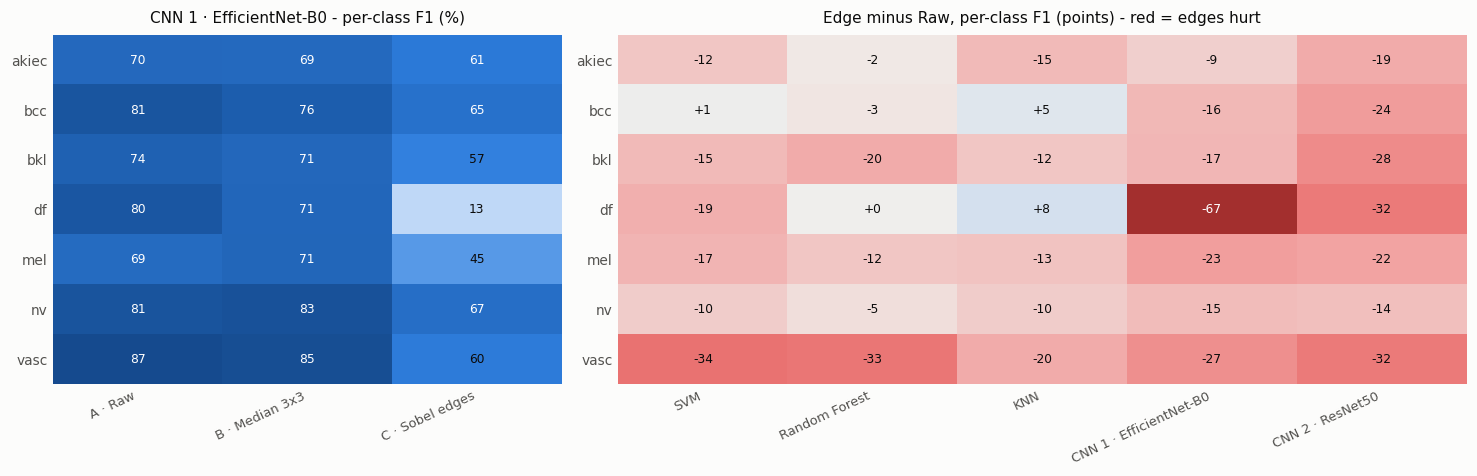

In [33]:
# Per-class F1: which lesion types lose most when only edges remain (Discussion Q5).
pc_rows = []
for (mname, s), run in RUNS.items():
    p, r, f1, sup = precision_recall_fscore_support(Y["test"], run["pred"], labels=LABELS, zero_division=0)
    for c in LABELS:
        pc_rows.append({"Model": mname, "Set": s, "Class": classes[c], "Precision (%)": 100 * p[c],
                        "Recall (%)": 100 * r[c], "F1-Score (%)": 100 * f1[c], "Support": int(sup[c])})
PER_CLASS = pd.DataFrame(pc_rows)
pc = PER_CLASS.pivot_table(index="Class", columns=["Model", "Set"], values="F1-Score (%)")
best_grid = pc[BEST_MODEL].reindex(index=classes, columns=SET_ORDER)
drop_grid = pd.DataFrame({m: pc[(m, "Edge")] - pc[(m, "Raw")] for m in MODEL_ORDER}).reindex(classes)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4), gridspec_kw={"width_ratios": [3, 5]})
vmax = max(float(np.nanmax(np.abs(drop_grid.to_numpy()))), 1.0)
for ax, grid, cmap_, norm, title, fmt in (
        (axes[0], best_grid, SEQ_CMAP, Normalize(0, 100), "%s - per-class F1 (%%)" % BEST_MODEL, "%.0f"),
        (axes[1], drop_grid, cmap_from(DIVERGING), Normalize(-vmax, vmax),
         "Edge minus Raw, per-class F1 (points) - red = edges hurt", "%+.0f")):
    vals = grid.to_numpy(dtype=float)
    ax.imshow(vals, cmap=cmap_, norm=norm, aspect="auto")
    ax.set_xticks(range(vals.shape[1]))
    ax.set_xticklabels([SET_LABEL.get(c, c) for c in grid.columns], rotation=25, ha="right", fontsize=8.5)
    ax.set_yticks(range(len(classes)))
    ax.set_yticklabels(classes)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    diverging = norm.vmin < 0
    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            t = float(norm(vals[i, j]))
            dark = abs(t - 0.5) > 0.3 if diverging else t > 0.6     # white ink only on the dark ends
            ax.text(j, i, fmt % vals[i, j], ha="center", va="center", fontsize=8,
                    color="#ffffff" if dark else INK_PRIMARY)
    ax.set_title(title, fontsize=10, pad=8)
fig.tight_layout()
save_fig(fig, "task6_per_class",
         "Figure 13. Left: per-class F1 of the best model on each set. Right: per-class F1 change from raw "
         "to edge images for every model.")

---
## 13 · What a CNN's first layer learns (Discussion Question 6)

A CNN is never *told* to find edges. Below are the 64 first-layer filters of the ImageNet ResNet50 used
in Section 10, together with the ones whose responses on our lesion images correlate best with Sobel
$G_x$ and $G_y$. Many of them turn out to be oriented edge and colour-opponent detectors that the
network learned for itself. They also keep colour, which a grey-level edge map throws away.

6 of 64 first-layer filters respond like a Sobel operator (|r| > 0.5, mean over 4 images).
Best match to Gx: filter #54 (r = -0.64).  Best match to Gy: filter #8 (r = -0.62).


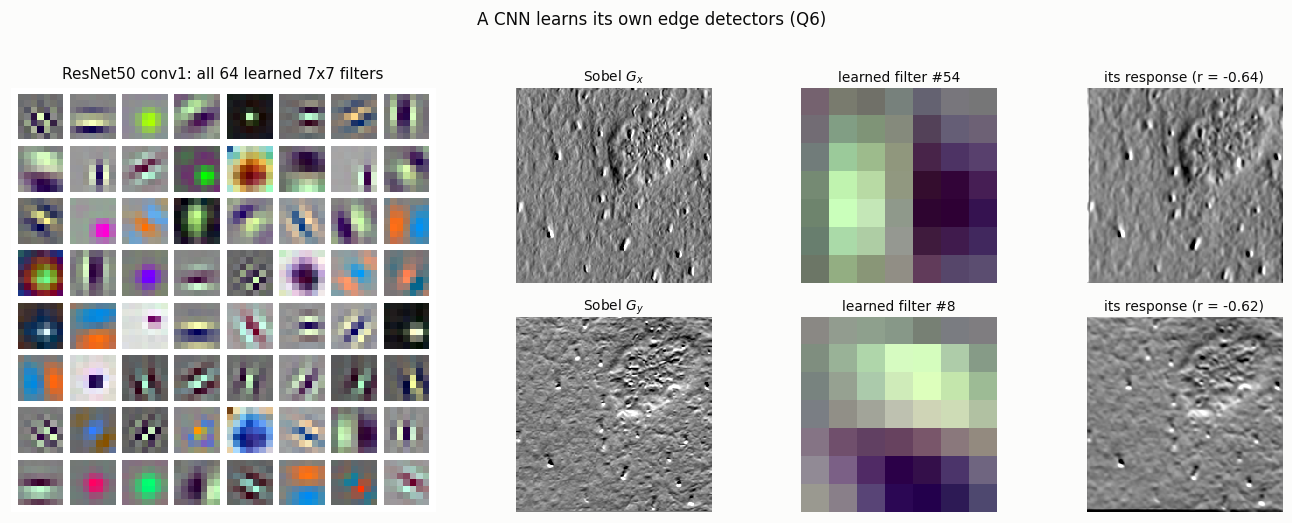

In [34]:
r50 = torchvision.models.resnet50(weights="DEFAULT").eval()
W1 = r50.conv1.weight.detach().float()                    # [64, 3, 7, 7]
del r50

# (a) all 64 filters, each scaled to [0, 1] for display
lo_w = W1.amin(dim=(1, 2, 3), keepdim=True)
hi_w = W1.amax(dim=(1, 2, 3), keepdim=True)
tiles = ((W1 - lo_w) / (hi_w - lo_w).clamp_min(1e-8)).permute(0, 2, 3, 1).numpy()
mosaic = np.ones((8 * 8 + 1, 8 * 8 + 1, 3))
for k in range(64):
    y0, x0 = 1 + (k // 8) * 8, 1 + (k % 8) * 8
    mosaic[y0:y0 + 7, x0:x0 + 7] = tiles[k]

# (b) correlate every filter's response with Sobel Gx / Gy, averaged over the example images
cx, cy = np.zeros(64), np.zeros(64)
with torch.no_grad():
    for i in EXAMPLES:
        resp = F.conv2d(to_input(X["test"][i:i + 1]).float(), W1.to(device), padding=3)[0].cpu().numpy()
        gx, gy, _ = sobel(gray_u8(X["test"][i]))
        flat = resp.reshape(64, -1)
        flat = flat - flat.mean(1, keepdims=True)
        for g_, acc in ((gx, cx), (gy, cy)):
            v = g_.ravel() - g_.mean()
            acc += (flat @ v) / (np.linalg.norm(flat, axis=1) * np.linalg.norm(v) + 1e-12)
cx /= len(EXAMPLES)
cy /= len(EXAMPLES)
kx, ky = int(np.argmax(np.abs(cx))), int(np.argmax(np.abs(cy)))
edge_like = int((np.maximum(np.abs(cx), np.abs(cy)) > 0.5).sum())
CONV1_STATS = {"edge_like": edge_like, "best_rx": float(abs(cx[kx])), "best_ry": float(abs(cy[ky])),
               "kx": kx, "ky": ky, "n_images": len(EXAMPLES)}
print("%d of 64 first-layer filters respond like a Sobel operator (|r| > 0.5, mean over %d images)."
      % (edge_like, len(EXAMPLES)))
print("Best match to Gx: filter #%d (r = %+.2f).  Best match to Gy: filter #%d (r = %+.2f)."
      % (kx, cx[kx], ky, cy[ky]))

ex = EXAMPLES[0]
resp = F.conv2d(to_input(X["test"][ex:ex + 1]).float(), W1.to(device), padding=3)[0].cpu().numpy()
gx, gy, _ = sobel(gray_u8(X["test"][ex]))
fig = plt.figure(figsize=(12.5, 4.6))
gs = fig.add_gridspec(2, 4, width_ratios=[1.75, 1, 1, 1])
ax = fig.add_subplot(gs[:, 0])
ax.imshow(mosaic, interpolation="nearest")
bare(ax)
ax.set_title("ResNet50 conv1: all 64 learned 7x7 filters", fontsize=10, pad=6)
for r, (lab, g_, k, c) in enumerate((("G_x", gx, kx, cx[kx]), ("G_y", gy, ky, cy[ky]))):
    panels = [(show_signed(g_), r"Sobel $%s$" % lab),
              (tiles[k], "learned filter #%d" % k),
              (show_signed(np.sign(c) * resp[k]), "its response (r = %+.2f)" % c)]
    for j, (img, title) in enumerate(panels):
        a = fig.add_subplot(gs[r, j + 1])
        a.imshow(img, cmap="gray" if img.ndim == 2 else None, vmin=0, vmax=1, interpolation="nearest")
        bare(a)
        a.set_title(title, fontsize=9, pad=4)
fig.suptitle("A CNN learns its own edge detectors (Q6)", fontsize=11, y=1.02)
fig.tight_layout()
save_fig(fig, "q6_learned_edge_filters",
         "Figure 14. First-layer filters of the ImageNet ResNet50 and the two whose responses best match Sobel "
         "Gx and Gy on the example lesion (responses sign-aligned with Sobel for display).")

---
## 14 · Cross-lab context (Question 7)

Lab 01 used a different dataset (ISIC, 9 classes), so its numbers are context rather than a like-for-
like comparison. Lab 02 used this exact split with frozen backbones. Its Raw and Median rows
correspond to Sets A and B, and its Sobel row to an edge input.

In [35]:
print("Lab 01 (ISIC 9-class, frozen backbone + linear probe):")
display(pd.DataFrame(LAB01_TABLE1, columns=["Model", "Accuracy (%)", "Macro-F1 (%)"]).style
        .format(precision=1).hide(axis="index"))

print("Lab 02 (HAM10000, same split, frozen backbone + linear probe):")
lab02 = pd.DataFrame(LAB02_REFERENCE, columns=["Model", "Input", "Accuracy (%)", "Macro-F1 (%)"])
display(lab02.pivot(index="Model", columns="Input", values="Macro-F1 (%)")[["Raw", "Median 3x3", "Sobel"]]
        .style.format(precision=1))

print("Lab 03 - mean over all five classifiers, by input set:")
SET_SUMMARY = (RESULTS.groupby("Set")[["Accuracy (%)", "F1-Score (%)", "Balanced Acc (%)", "AUC (%)"]]
               .mean().reindex(SET_ORDER))
SET_SUMMARY.index = [SET_LABEL[s] for s in SET_SUMMARY.index]
display(SET_SUMMARY.style.format(precision=2))

print("Lab 03 - best input set for each classifier (test macro-F1):")
BEST_SET = RESULTS.loc[RESULTS.groupby("Model")["F1-Score (%)"].idxmax(), ["Model", "Set", "F1-Score (%)"]]
BEST_SET = BEST_SET.set_index("Model").reindex(MODEL_ORDER).reset_index()
display(BEST_SET.style.format(precision=2).hide(axis="index"))

Lab 01 (ISIC 9-class, frozen backbone + linear probe):


Model,Accuracy (%),Macro-F1 (%)
EfficientNet-B0,57.6,53.6
ResNet18,51.7,49.4
ResNet50,49.2,45.7
ResNet101,47.5,42.8
DenseNet121,47.5,45.1
VGG16,39.8,36.4
VGG19,39.0,34.3
AlexNet,35.6,31.0


Lab 02 (HAM10000, same split, frozen backbone + linear probe):


Input,Raw,Median 3x3,Sobel
Model,,,
EfficientNet-B0,57.4,57.1,43.4
ResNet18,53.2,57.8,41.0
ResNet50,55.5,59.9,39.3


Lab 03 - mean over all five classifiers, by input set:


,Accuracy (%),F1-Score (%),Balanced Acc (%),AUC (%)
A · Raw,64.76,63.16,63.09,90.31
B · Median 3x3,62.70,60.62,60.24,89.73
C · Sobel edges,50.02,46.41,47.81,81.42


Lab 03 - best input set for each classifier (test macro-F1):


Model,Set,F1-Score (%)
SVM,Raw,60.58
Random Forest,Raw,51.25
KNN,Raw,49.27
CNN 1 · EfficientNet-B0,Raw,77.38
CNN 2 · ResNet50,Raw,77.31


---
## 15 · Export

Everything goes into `results/`:
- every CSV, and every figure as a PNG;
- a `config.json` that records the exact protocol;
- **`Lab 03 - Results.docx`** with Tables 1–3 in the sheet's format, the supporting tables and all
  figures;
- **`questions_evidence.md`**, the numbers behind Discussion Questions 1–7.

The results are then zipped for download.

In [36]:
def _fmt(v):
    if isinstance(v, str):
        return v
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "-"
    if isinstance(v, (int, np.integer)):
        return str(v)
    return "%.2f" % v


def _md(obj, index=True):
    """DataFrame / Series -> Markdown table (hand-rolled: pandas' to_markdown needs `tabulate`)."""
    df = obj.to_frame() if isinstance(obj, pd.Series) else obj.copy()
    if index:
        df = df.reset_index()
    df.columns = [str(c) for c in df.columns]
    esc = lambda t: str(t).replace("|", "\\|")
    cells = [[esc(_fmt(v)) for v in row] for row in df.itertuples(index=False)]
    header = [esc(c) for c in df.columns]
    widths = [max([len(header[i])] + [len(r[i]) for r in cells]) for i in range(len(header))]
    out = ["| " + " | ".join(h.ljust(w) for h, w in zip(header, widths)) + " |",
           "| " + " | ".join("-" * w for w in widths) + " |"]
    out += ["| " + " | ".join(c.ljust(w) for c, w in zip(r, widths)) + " |" for r in cells]
    return "\n".join(out)


def mean_f1_change(models, to_set):
    return float(np.mean([R.loc[(m, to_set), "F1-Score (%)"] - R.loc[(m, "Raw"), "F1-Score (%)"] for m in models]))


def build_evidence():
    L = ["# Lab 03 - computed evidence for the discussion questions\n\n",
         "_Auto-generated by the Lab 03 notebook; every number comes from this run._\n"]
    L.append("\n## Setup\n\n")
    L.append("- HAM10000, %d classes; grouped split by lesion_id; train %d / val %d / test %d images (Lab 02's split).\n"
             % (N_CLASSES, len(Y["train"]), len(Y["val"]), len(Y["test"])))
    L.append("- Set B = Median %dx%d (Lab 02's best filter). Set C = **%s** (best validation macro-F1 of %d edge candidates).\n"
             % (cfg.denoise_median_ksize, cfg.denoise_median_ksize, SET_C, len(EDGE_CANDIDATES)))
    L.append("- Noise: Gaussian sigma = %g grey levels; salt-and-pepper on %.0f%% of pixels. Filters: Gaussian %dx%d "
             "(sigma %g), Median %dx%d. Tables 1-2 average over %d test images.\n"
             % (cfg.gaussian_noise_sigma, 100 * cfg.sp_amount, cfg.denoise_gaussian_ksize, cfg.denoise_gaussian_ksize,
                cfg.denoise_gaussian_sigma, cfg.denoise_median_ksize, cfg.denoise_median_ksize, len(ANALYSIS_IDX)))

    L.append("\n## Q1 - Which edge detector is most sensitive to noise?\n\n")
    q1 = pd.DataFrame({
        "F1 vs clean, Gaussian noise (%)": [T1_FULL.loc[(d, "Gaussian", "None"), "F1 vs clean (%)"] for d in DETECTORS],
        "Inflation, Gaussian (x)": [T1_FULL.loc[(d, "Gaussian", "None"), "Edge inflation (x)"] for d in DETECTORS],
        "F1 vs clean, S&P noise (%)": [T1_FULL.loc[(d, "Salt & Pepper", "None"), "F1 vs clean (%)"] for d in DETECTORS],
        "Inflation, S&P (x)": [T1_FULL.loc[(d, "Salt & Pepper", "None"), "Edge inflation (x)"] for d in DETECTORS],
    }, index=pd.Index(DETECTORS, name="Detector"))
    q1["Mean F1 (%)"] = q1[["F1 vs clean, Gaussian noise (%)", "F1 vs clean, S&P noise (%)"]].mean(axis=1)
    q1 = q1.sort_values("Mean F1 (%)")
    L.append(_md(q1))
    L.append("\n\n**Most noise-sensitive: `%s`** (mean F1 vs clean %.1f%%). Most robust: `%s` (%.1f%%).\n"
             % (q1.index[0], q1["Mean F1 (%)"].iloc[0], q1.index[-1], q1["Mean F1 (%)"].iloc[-1]))

    L.append("\n## Q2 - How did Gaussian and Median filtering change the edges?\n\n")
    for noise in ("Gaussian", "Salt & Pepper"):
        q2 = pd.DataFrame({prep: [T1_FULL.loc[(d, noise, prep), "F1 vs clean (%)"] for d in DETECTORS] for prep in PREPS},
                          index=pd.Index(DETECTORS, name="Detector"))
        L.append("F1 vs clean edges under **%s** noise, by preprocessing:\n\n%s\n\n" % (noise, _md(q2)))
        q2s = pd.DataFrame({prep: [T1_FULL.loc[(d, noise, prep), "Specks (%)"] for d in DETECTORS] for prep in PREPS},
                           index=pd.Index(DETECTORS, name="Detector"))
        L.append("Specks (%% of fragments under 10 px) under **%s** noise:\n\n%s\n\n" % (noise, _md(q2s)))
    L.append("Image PSNR against the clean image (dB):\n\n%s\n" % _md(PSNR_TABLE))

    L.append("\n## Q3 - How did the Canny thresholds change the edges?\n\n")
    L.append(_md(T2_FULL))
    sweep = pd.DataFrame({"high threshold": HIGHS, **{"edge px %% (%dx%d)" % (k, k): SWEEP[k]["density"] for k in KSIZES},
                          **{"noise F1 %% (%dx%d)" % (k, k): SWEEP[k]["f1"] for k in KSIZES}})
    L.append("\n\nThreshold sweep (low = high / 3):\n\n%s\n" % _md(sweep, index=False))
    L.append("\nBest Canny configuration as a classifier input (validation): **%s**.\n" % BEST_CANNY)

    L.append("\n## Q4 - Did edge-only images help or hurt classification?\n\n")
    q4 = pd.DataFrame({
        "Acc Raw (%)": [R.loc[(m, "Raw"), "Accuracy (%)"] for m in MODEL_ORDER],
        "Acc Edge (%)": [R.loc[(m, "Edge"), "Accuracy (%)"] for m in MODEL_ORDER],
        "Macro-F1 Raw (%)": [R.loc[(m, "Raw"), "F1-Score (%)"] for m in MODEL_ORDER],
        "Macro-F1 Edge (%)": [R.loc[(m, "Edge"), "F1-Score (%)"] for m in MODEL_ORDER],
    }, index=pd.Index(MODEL_ORDER, name="Model"))
    q4["Change in Acc"] = q4["Acc Edge (%)"] - q4["Acc Raw (%)"]
    q4["Change in Macro-F1"] = q4["Macro-F1 Edge (%)"] - q4["Macro-F1 Raw (%)"]
    L.append(_md(q4))
    worse = int((q4["Change in Macro-F1"] < 0).sum())
    L.append("\n\nEdge images lowered macro-F1 for **%d of %d** classifiers (mean change %+.2f points; accuracy %+.2f).\n"
             % (worse, len(q4), q4["Change in Macro-F1"].mean(), q4["Change in Acc"].mean()))

    L.append("\n## Q5 - What is lost when only edges remain?\n\n")
    q5 = pd.DataFrame({"Mean F1 Raw (%)": [pc[[(m, "Raw") for m in MODEL_ORDER]].loc[c].mean() for c in classes],
                       "Mean F1 Edge (%)": [pc[[(m, "Edge") for m in MODEL_ORDER]].loc[c].mean() for c in classes]},
                      index=pd.Index(classes, name="Class"))
    q5["Change"] = q5["Mean F1 Edge (%)"] - q5["Mean F1 Raw (%)"]
    q5 = q5.sort_values("Change")
    L.append("Per-class F1, averaged over all five classifiers:\n\n" + _md(q5))
    L.append("\n\nLargest per-class loss: **`%s`** (%+.1f points). Smallest: `%s` (%+.1f).\n"
             % (q5.index[0], q5["Change"].iloc[0], q5.index[-1], q5["Change"].iloc[-1]))

    L.append("\n## Q6 - Hand-crafted edges vs features a CNN learns\n\n")
    frozen, tuned = list(CLASSIC), [CNN_NAMES[m] for m in cfg.cnn_models]
    L.append("- Mean macro-F1 change Raw -> Edge, classifiers on **frozen** ImageNet features: %+.2f points.\n"
             % mean_f1_change(frozen, "Edge"))
    L.append("- Mean macro-F1 change Raw -> Edge, **fine-tuned** CNNs: %+.2f points.\n" % mean_f1_change(tuned, "Edge"))
    L.append("- ResNet50 conv1: %d of 64 learned filters correlate with a Sobel operator at |r| > 0.5 (mean over %d images); "
             "best |r| = %.2f for G_x (filter #%d), %.2f for G_y (filter #%d).\n"
             % (CONV1_STATS["edge_like"], CONV1_STATS["n_images"], CONV1_STATS["best_rx"], CONV1_STATS["kx"],
                CONV1_STATS["best_ry"], CONV1_STATS["ky"]))

    L.append("\n## Q7 - Which representation worked best across Labs 01-03?\n\n")
    L.append("Lab 03, mean over all five classifiers:\n\n" + _md(SET_SUMMARY) + "\n\n")
    L.append("Best set per classifier (test macro-F1):\n\n" + _md(BEST_SET, index=False) + "\n\n")
    L.append("Mean macro-F1 change vs Raw: Filtered %+.2f, Edge %+.2f points.\n\n"
             % (mean_f1_change(MODEL_ORDER, "Filtered"), mean_f1_change(MODEL_ORDER, "Edge")))
    L.append("Lab 02 reference (same split, frozen backbones, macro-F1 %%):\n\n%s\n"
             % _md(lab02.pivot(index="Model", columns="Input", values="Macro-F1 (%)")[["Raw", "Median 3x3", "Sobel"]]))

    L.append("\n## Table 3 - full results\n\n" + _md(RESULTS[["Model", "Set"] + METRIC_COLS], index=False) + "\n")
    return "".join(L)


def write_docx(path):
    try:
        from docx import Document
        from docx.shared import Inches, Pt
    except ImportError:
        print("[warn] python-docx not installed - skipping the .docx report")
        return
    doc = Document()
    doc.add_heading("Lab 03 - Edge Detection Techniques and Their Impact on Classification Performance", level=1)
    p = doc.add_paragraph().add_run(
        "Dataset: HAM10000, %d classes (%s). Lab 02's grouped-stratified split by lesion_id: train %d, val %d, "
        "test %d images. Set A raw; Set B Median %dx%d; Set C %s edges (best validation macro-F1 of %d candidates). "
        "SVM / Random Forest / KNN on frozen %s features; %s fine-tuned end-to-end for %d epochs. Precision, recall "
        "and F1 are macro-averaged. Device: %s."
        % (N_CLASSES, ", ".join(classes), len(Y["train"]), len(Y["val"]), len(Y["test"]), cfg.denoise_median_ksize,
           cfg.denoise_median_ksize, SET_C, len(EDGE_CANDIDATES), cfg.feature_backbone, " and ".join(cfg.cnn_models),
           cfg.ft_epochs, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"))
    p.font.size = Pt(9)

    def add_table(frame, caption, note=None, font=8, index=False):
        doc.add_heading(caption, level=2)
        frame = frame.reset_index() if index else frame
        table = doc.add_table(rows=1, cols=len(frame.columns))
        table.style = "Table Grid"
        for i, col in enumerate(frame.columns):
            cell = table.rows[0].cells[i]
            cell.text = str(col)
            for run in cell.paragraphs[0].runs:
                run.bold = True
                run.font.size = Pt(font)
        for row in frame.itertuples(index=False):
            cells = table.add_row().cells
            for i, v in enumerate(row):
                cells[i].text = _fmt(v)
                for run in cells[i].paragraphs[0].runs:
                    run.font.size = Pt(font)
        if note:
            doc.add_paragraph().add_run(note).font.size = Pt(8)

    add_table(TABLE1_DOC, "Table 1. Effect of Noise and Preprocessing on Edge Detection",
              "Mean over %d test images. Edge Quality: tolerant F1 (1 px) of the edge map against the clean-image edge "
              "map; false = detected edges not near a clean edge, missed = clean edges not found. Noise Sensitivity: "
              "Low F1 >= 75%%, Medium 50-75%%, High < 50%%; x = edge pixels relative to the clean image. Thresholds "
              "set by Otsu on the clean image (after the same filter) and frozen before noise is added." % len(ANALYSIS_IDX))
    add_table(TABLE2_DOC, "Table 2. Canny Parameter Analysis",
              "Kernel size = Gaussian smoothing before cv2.Canny (L2 gradient). Best configuration as a classifier "
              "input: %s." % BEST_CANNY)
    add_table(TABLE3_DOC, "Table 3. Cross-Lab Classification Performance Comparison",
              "Precision / Recall / F1-Score / time cells read Raw / Filtered / Edge. SVM, Random Forest and KNN use "
              "frozen %s features; timings include feature extraction. Inference time is per image, batched on the GPU."
              % cfg.feature_backbone, font=7.5)

    doc.add_heading("Supporting tables", level=1)
    add_table(T1_FULL.round(2), "Table S1. Edge statistics for every detector and condition", font=6.5, index=True)
    add_table(PSNR_TABLE.round(2), "Table S2. Image PSNR after noise and filtering (dB)", index=True)
    add_table(T2_FULL.round(2), "Table S3. Canny configurations - full statistics", font=7, index=True)
    add_table(SCREEN_DF.round(2), "Table S4. Edge-representation screening (validation split)")
    add_table(RESULTS[["Model", "Set"] + METRIC_COLS].round(2), "Table S5. Full test metrics", font=6.5)
    add_table(best_grid.round(1), "Table S6. Per-class F1 of the best model (%s)" % BEST_MODEL, index=True)
    add_table(CLASS_COUNTS, "Table S7. HAM10000 class distribution")

    doc.add_heading("Figures", level=1)
    for _name, (png, caption) in FIGURES.items():
        doc.add_picture(png, width=Inches(6.3))
        doc.add_paragraph().add_run(caption).font.size = Pt(8.5)
    doc.save(str(path))
    print("Wrote", path)


out = Path(cfg.out_dir)
T1_FULL.to_csv(out / "table1_full.csv")
TABLE1_DOC.to_csv(out / "table1_task_format.csv", index=False)
PSNR_TABLE.to_csv(out / "psnr.csv")
T2_FULL.to_csv(out / "table2_full.csv")
TABLE2_DOC.to_csv(out / "table2_task_format.csv", index=False)
SCREEN_DF.to_csv(out / "setC_screening.csv", index=False)
RESULTS.to_csv(out / "table3_full.csv", index=False)
TABLE3_DOC.to_csv(out / "table3_task_format.csv", index=False)
PER_CLASS.to_csv(out / "per_class_metrics.csv", index=False)
CLASS_COUNTS.to_csv(out / "class_distribution.csv", index=False)
hist_rows = []
for (m, s), run in RUNS.items():
    h = run["history"]
    if not h:
        continue
    for k, e in enumerate(h["epoch"]):
        hist_rows.append({"Model": m, "Set": s, "Epoch": e, "Train Loss": h["train_loss"][k],
                          "Train Acc (%)": h["train_acc"][k], "Val Loss": h["val_loss"][k],
                          "Val Acc (%)": h["val_acc"][k], "Val Macro-F1 (%)": h["val_f1"][k]})
pd.DataFrame(hist_rows).to_csv(out / "training_history.csv", index=False)
with open(out / "config.json", "w", encoding="utf-8") as fh:
    json.dump({**asdict(cfg), "canny_configs": CANNY_CONFIGS, "set_c": SET_C, "best_canny": BEST_CANNY,
               "best_model": BEST_MODEL, "classes": classes, "n_train": len(Y["train"]), "n_val": len(Y["val"]),
               "n_test": len(Y["test"])}, fh, indent=2, default=str)
with open(out / "questions_evidence.md", "w", encoding="utf-8") as fh:
    fh.write(build_evidence())
write_docx(out / "Lab 03 - Results.docx")
for f in sorted(os.listdir(out)):
    print(" ", f)

Wrote results/Lab 03 - Results.docx
  Lab 03 - Results.docx
  class_distribution.csv
  config.json
  per_class_metrics.csv
  psnr.csv
  q6_learned_edge_filters.png
  questions_evidence.md
  setC_screening.csv
  table1_full.csv
  table1_task_format.csv
  table2_full.csv
  table2_task_format.csv
  table3_full.csv
  table3_partial.csv
  table3_task_format.csv
  task1_binary_edges.png
  task1_edge_comparison.png
  task2_noise_edges.png
  task2_noise_sensitivity.png
  task3_canny_configs.png
  task3_canny_sweep.png
  task4_setC_screening.png
  task4_sets.png
  task6_confusion_best.png
  task6_macro_f1_all_models.png
  task6_metrics_best.png
  task6_per_class.png
  task6_training_curves.png
  training_history.csv


In [37]:
# The computed evidence for Discussion Questions 1-7.
display(Markdown(open(Path(cfg.out_dir) / "questions_evidence.md", encoding="utf-8").read()))

# Lab 03 - computed evidence for the discussion questions

_Auto-generated by the Lab 03 notebook; every number comes from this run._

## Setup

- HAM10000, 7 classes; grouped split by lesion_id; train 1969 / val 524 / test 525 images (Lab 02's split).
- Set B = Median 3x3 (Lab 02's best filter). Set C = **Sobel** (best validation macro-F1 of 8 edge candidates).
- Noise: Gaussian sigma = 20 grey levels; salt-and-pepper on 5% of pixels. Filters: Gaussian 5x5 (sigma 1), Median 3x3. Tables 1-2 average over 70 test images.

## Q1 - Which edge detector is most sensitive to noise?

| Detector  | F1 vs clean, Gaussian noise (%) | Inflation, Gaussian (x) | F1 vs clean, S&P noise (%) | Inflation, S&P (x) | Mean F1 (%) |
| --------- | ------------------------------- | ----------------------- | -------------------------- | ------------------ | ----------- |
| Canny     | 55.78                           | 2.14                    | 18.16                      | 13.95              | 36.97       |
| LoG       | 45.02                           | 7.01                    | 48.56                      | 5.37               | 46.79       |
| Laplacian | 54.59                           | 7.42                    | 62.98                      | 3.16               | 58.78       |
| Prewitt   | 54.86                           | 4.80                    | 66.30                      | 2.56               | 60.58       |
| Sobel     | 55.01                           | 4.89                    | 66.31                      | 2.58               | 60.66       |

**Most noise-sensitive: `Canny`** (mean F1 vs clean 37.0%). Most robust: `Sobel` (60.7%).

## Q2 - How did Gaussian and Median filtering change the edges?

F1 vs clean edges under **Gaussian** noise, by preprocessing:

| Detector  | None  | Gaussian Filter | Median Filter |
| --------- | ----- | --------------- | ------------- |
| Sobel     | 55.01 | 62.42           | 60.04         |
| Prewitt   | 54.86 | 62.40           | 59.92         |
| Laplacian | 54.59 | 54.77           | 55.25         |
| LoG       | 45.02 | 46.87           | 47.38         |
| Canny     | 55.78 | 32.06           | 51.47         |

Specks (% of fragments under 10 px) under **Gaussian** noise:

| Detector  | None  | Gaussian Filter | Median Filter |
| --------- | ----- | --------------- | ------------- |
| Sobel     | 30.77 | 82.33           | 82.06         |
| Prewitt   | 37.88 | 84.19           | 85.00         |
| Laplacian | 6.43  | 94.15           | 79.75         |
| LoG       | 84.59 | 78.62           | 83.65         |
| Canny     | 1.89  | 0.36            | 0.36          |

F1 vs clean edges under **Salt & Pepper** noise, by preprocessing:

| Detector  | None  | Gaussian Filter | Median Filter |
| --------- | ----- | --------------- | ------------- |
| Sobel     | 66.31 | 60.51           | 95.11         |
| Prewitt   | 66.30 | 60.24           | 95.31         |
| Laplacian | 62.98 | 56.23           | 75.49         |
| LoG       | 48.56 | 48.41           | 84.75         |
| Canny     | 18.16 | 29.45           | 53.40         |

Specks (% of fragments under 10 px) under **Salt & Pepper** noise:

| Detector  | None  | Gaussian Filter | Median Filter |
| --------- | ----- | --------------- | ------------- |
| Sobel     | 52.14 | 50.79           | 73.56         |
| Prewitt   | 53.48 | 52.89           | 72.51         |
| Laplacian | 62.61 | 83.15           | 90.75         |
| LoG       | 81.36 | 65.42           | 92.13         |
| Canny     | 6.81  | 5.24            | 0.54          |

Image PSNR against the clean image (dB):

| Noise Type    | None  | Gaussian Filter | Median Filter |
| ------------- | ----- | --------------- | ------------- |
| Gaussian      | 22.13 | 32.30           | 29.53         |
| Salt & Pepper | 18.53 | 28.74           | 42.56         |

## Q3 - How did the Canny thresholds change the edges?

| Configuration | Low | High | Kernel | Edge px (count) | Edge px (%) | Fragments | Mean fragment (px) | Specks (%) | Thickness (px) | F1 under Gaussian noise (%) | F1 under S&P noise (%) |
| ------------- | --- | ---- | ------ | --------------- | ----------- | --------- | ------------------ | ---------- | -------------- | --------------------------- | ---------------------- |
| Canny-1       | 30  | 100  | 3x3    | 810.97          | 1.62        | 11.90     | 54.85              | 3.19       | 1.32           | 12.43                       | 15.21                  |
| Canny-2       | 50  | 150  | 3x3    | 235.63          | 0.47        | 3.21      | 34.16              | 1.60       | 1.41           | 25.69                       | 8.84                   |
| Canny-3       | 100 | 200  | 3x3    | 56.27           | 0.11        | 1.16      | 15.59              | 1.43       | 1.42           | 59.75                       | 10.23                  |
| Canny-4       | 50  | 150  | 5x5    | 112.13          | 0.22        | 1.43      | 28.40              | 0.29       | 1.40           | 55.78                       | 18.16                  |

Threshold sweep (low = high / 3):

| high threshold | edge px % (3x3) | edge px % (5x5) | edge px % (7x7) | noise F1 % (3x3) | noise F1 % (5x5) | noise F1 % (7x7) |
| -------------- | --------------- | --------------- | --------------- | ---------------- | ---------------- | ---------------- |
| 40             | 11.38           | 7.48            | 4.25            | 48.38            | 35.85            | 27.41            |
| 60             | 5.47            | 3.31            | 1.70            | 26.83            | 19.84            | 32.89            |
| 80             | 2.76            | 1.61            | 0.75            | 15.68            | 18.61            | 49.27            |
| 100            | 1.54            | 0.86            | 0.38            | 12.46            | 27.88            | 54.04            |
| 120            | 0.94            | 0.48            | 0.16            | 13.18            | 39.80            | 65.12            |
| 140            | 0.59            | 0.28            | 0.09            | 19.79            | 54.31            | 67.77            |
| 160            | 0.40            | 0.15            | 0.03            | 32.76            | 55.28            | 77.58            |
| 180            | 0.28            | 0.09            | 0.01            | 43.77            | 66.33            | 77.11            |
| 200            | 0.16            | 0.05            | 0.01            | 47.97            | 65.23            | 79.44            |
| 220            | 0.09            | 0.02            | 0.00            | 52.13            | 87.70            | -                |
| 240            | 0.05            | 0.01            | 0.00            | 64.58            | 75.36            | -                |
| 260            | 0.03            | 0.01            | 0.00            | 69.02            | 73.53            | -                |
| 280            | 0.02            | 0.00            | 0.00            | 79.30            | 42.20            | -                |

Best Canny configuration as a classifier input (validation): **Canny-1**.

## Q4 - Did edge-only images help or hurt classification?

| Model                   | Acc Raw (%) | Acc Edge (%) | Macro-F1 Raw (%) | Macro-F1 Edge (%) | Change in Acc | Change in Macro-F1 |
| ----------------------- | ----------- | ------------ | ---------------- | ----------------- | ------------- | ------------------ |
| SVM                     | 61.90       | 49.71        | 60.58            | 45.25             | -12.19        | -15.34             |
| Random Forest           | 56.95       | 47.43        | 51.25            | 40.64             | -9.52         | -10.61             |
| KNN                     | 53.14       | 43.24        | 49.27            | 41.08             | -9.90         | -8.20              |
| CNN 1 · EfficientNet-B0 | 75.81       | 56.19        | 77.38            | 52.49             | -19.62        | -24.89             |
| CNN 2 · ResNet50        | 76.00       | 53.52        | 77.31            | 52.62             | -22.48        | -24.69             |

Edge images lowered macro-F1 for **5 of 5** classifiers (mean change -16.74 points; accuracy -14.74).

## Q5 - What is lost when only edges remain?

Per-class F1, averaged over all five classifiers:

| Class | Mean F1 Raw (%) | Mean F1 Edge (%) | Change |
| ----- | --------------- | ---------------- | ------ |
| vasc  | 84.97           | 55.50            | -29.47 |
| df    | 39.96           | 17.88            | -22.07 |
| bkl   | 65.23           | 46.92            | -18.30 |
| mel   | 59.07           | 41.55            | -17.52 |
| akiec | 56.31           | 44.77            | -11.54 |
| nv    | 73.48           | 62.64            | -10.84 |
| bcc   | 63.11           | 55.64            | -7.48  |

Largest per-class loss: **`vasc`** (-29.5 points). Smallest: `bcc` (-7.5).

## Q6 - Hand-crafted edges vs features a CNN learns

- Mean macro-F1 change Raw -> Edge, classifiers on **frozen** ImageNet features: -11.38 points.
- Mean macro-F1 change Raw -> Edge, **fine-tuned** CNNs: -24.79 points.
- ResNet50 conv1: 6 of 64 learned filters correlate with a Sobel operator at |r| > 0.5 (mean over 4 images); best |r| = 0.64 for G_x (filter #54), 0.62 for G_y (filter #8).

## Q7 - Which representation worked best across Labs 01-03?

Lab 03, mean over all five classifiers:

| index           | Accuracy (%) | F1-Score (%) | Balanced Acc (%) | AUC (%) |
| --------------- | ------------ | ------------ | ---------------- | ------- |
| A · Raw         | 64.76        | 63.16        | 63.09            | 90.31   |
| B · Median 3x3  | 62.70        | 60.62        | 60.24            | 89.73   |
| C · Sobel edges | 50.02        | 46.41        | 47.81            | 81.42   |

Best set per classifier (test macro-F1):

| Model                   | Set | F1-Score (%) |
| ----------------------- | --- | ------------ |
| SVM                     | Raw | 60.58        |
| Random Forest           | Raw | 51.25        |
| KNN                     | Raw | 49.27        |
| CNN 1 · EfficientNet-B0 | Raw | 77.38        |
| CNN 2 · ResNet50        | Raw | 77.31        |

Mean macro-F1 change vs Raw: Filtered -2.54, Edge -16.74 points.

Lab 02 reference (same split, frozen backbones, macro-F1 %):

| Model           | Raw   | Median 3x3 | Sobel |
| --------------- | ----- | ---------- | ----- |
| EfficientNet-B0 | 57.40 | 57.10      | 43.40 |
| ResNet18        | 53.20 | 57.80      | 41.00 |
| ResNet50        | 55.50 | 59.90      | 39.30 |

## Table 3 - full results

| Model                   | Set      | Accuracy (%) | Precision (%) | Recall (%) | F1-Score (%) | Balanced Acc (%) | AUC (%) | Weighted-F1 (%) | Training Time (s) | Inference Time (ms) | Val Macro-F1 (%) |
| ----------------------- | -------- | ------------ | ------------- | ---------- | ------------ | ---------------- | ------- | --------------- | ----------------- | ------------------- | ---------------- |
| SVM                     | Raw      | 61.90        | 66.57         | 58.38      | 60.58        | 58.38            | 87.54   | 61.78           | 4.33              | 21.99               | 62.33            |
| SVM                     | Filtered | 58.48        | 62.33         | 56.90      | 58.62        | 56.90            | 86.62   | 58.53           | 4.27              | 2.14                | 62.52            |
| SVM                     | Edge     | 49.71        | 45.89         | 45.93      | 45.25        | 45.93            | 80.00   | 48.90           | 4.58              | 2.29                | 50.46            |
| Random Forest           | Raw      | 56.95        | 53.59         | 50.04      | 51.25        | 50.04            | 87.45   | 56.03           | 18.48             | 20.62               | 48.97            |
| Random Forest           | Filtered | 55.62        | 52.34         | 46.67      | 48.09        | 46.67            | 86.70   | 54.63           | 19.40             | 0.80                | 49.05            |
| Random Forest           | Edge     | 47.43        | 43.32         | 40.50      | 40.64        | 40.50            | 80.09   | 45.81           | 18.13             | 0.80                | 46.61            |
| KNN                     | Raw      | 53.14        | 52.06         | 49.72      | 49.27        | 49.72            | 83.27   | 52.73           | 1.22              | 20.54               | 50.79            |
| KNN                     | Filtered | 52.19        | 61.54         | 47.25      | 47.98        | 47.25            | 84.24   | 51.80           | 1.21              | 0.73                | 50.69            |
| KNN                     | Edge     | 43.24        | 47.42         | 39.75      | 41.08        | 39.75            | 74.91   | 43.53           | 1.25              | 0.82                | 44.65            |
| CNN 1 · EfficientNet-B0 | Raw      | 75.81        | 76.75         | 78.32      | 77.38        | 78.32            | 96.51   | 75.79           | 150.90            | 0.60                | 77.01            |
| CNN 1 · EfficientNet-B0 | Filtered | 74.86        | 76.14         | 75.56      | 75.18        | 75.56            | 95.60   | 74.85           | 58.04             | 0.61                | 72.93            |
| CNN 1 · EfficientNet-B0 | Edge     | 56.19        | 51.26         | 55.81      | 52.49        | 55.81            | 86.58   | 56.73           | 57.91             | 0.63                | 54.04            |
| CNN 2 · ResNet50        | Raw      | 76.00        | 76.12         | 78.98      | 77.31        | 78.98            | 96.77   | 76.09           | 91.70             | 1.56                | 72.91            |
| CNN 2 · ResNet50        | Filtered | 72.38        | 72.51         | 74.81      | 73.23        | 74.81            | 95.52   | 72.33           | 82.48             | 1.11                | 76.23            |
| CNN 2 · ResNet50        | Edge     | 53.52        | 50.85         | 57.06      | 52.62        | 57.06            | 85.51   | 53.59           | 82.44             | 1.10                | 54.62            |


In [38]:
# Zip everything and download it.
archive = shutil.make_archive("lab03_results", "zip", cfg.out_dir)
print("Archive:", archive)
if IN_COLAB:
    from google.colab import files
    files.download(archive)
elif IN_KAGGLE:
    print("Saved in /kaggle/working - download it from the notebook's Output panel.")

Archive: /content/lab03_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
### Notes for the write-up
- **Set C is chosen with a frozen-feature probe.** The Section 7 screening uses frozen EfficientNet-B0
  features, so it finds the edge map that keeps the most *ImageNet-readable* information. A fine-tuned
  network could prefer a different map. Set `cfg.setC_override` to test another candidate.
- **Frozen vs fine-tuned is the Q6 story.** SVM, Random Forest and KNN only ever see frozen ImageNet
  features, so an edge map that looks nothing like an ImageNet photo should hurt them the most, while
  the fine-tuned CNNs can adapt. Compare the two groups' Raw → Edge drops (Q6 in the evidence file) to
  see whether that happened.
- **The test set is capped per class** (at most 120 images per class, 525 total). Its class mix is
  therefore *not* HAM10000's natural one. Quote macro-F1 and balanced accuracy, and treat
  differences of a point or two as noise.
- **Timings are relative, not absolute.** They depend on the GPU Colab assigns. Feature-classifier
  times include the CNN forward pass, so they are not just the cost of fitting an SVM.
- **Noise was added to the grey image**, which is what the edge detectors operate on. All thresholds
  were frozen on the clean image, so the noise measurements are not hidden by re-tuning.